# V8 · Frozen speech representations with TORGO development and UASpeech validation

**Research notebook.** TORGO waveforms → frozen WavLM or HuBERT → last four hidden layers (mean and standard deviation over time) → learned layer mixture and attention over each physical speaker’s utterances → a compact binary classifier. Set `DYSARTHRIA_V8_FUSION=1` before restarting the kernel to include a second arm that fuses engineered acoustic features.

The notebook contains the full TORGO experiment and a locked UASpeech zero-shot section. It does not import `v8.pipeline` or a previous version. All derived data live under this notebook’s `outputs/cache/dysarthria_detection_v8` directory. Matching V8 shards and checkpoints resume automatically.

**Output status:** The saved TORGO inventory, cross-validation results, and diagnostic figures are complete. UASpeech result cells at the end of this notebook are intentionally unexecuted until the external validation finishes. The M3 channel is primary; its labels are used only for final metrics after all-TORGO model fitting and threshold locking.

## 1. Environment and experiment settings

Use a Python kernel with `torch`, `torchaudio`, `librosa`, `soundfile`, `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `seaborn`, `kagglehub`, and `IPython`. Open the notebook from the project root or `v8/`; a standalone copied notebook also writes its own `outputs/` directory. Set `TORGO_DATASET_PATH` to an existing raw TORGO directory to avoid a KaggleHub download.

The default is WavLM Base with frozen pretrained weights and a learned layer mix. `Config` below contains the exact run settings; changing them makes a distinct V8 run.

In [75]:
from __future__ import annotations

import copy
import hashlib
import json
import os
import random
import re
import tempfile
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any

import librosa
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio
from scipy.special import expit
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.nn import functional as F


# Supports opening this notebook from the project root, v8/, or a copied folder.
_CWD = Path.cwd().resolve()
V8_DIR = _CWD / "v8" if (_CWD / "v8" / "dysarthria_v8.ipynb").is_file() else _CWD
ROOT = V8_DIR.parent
OUT = V8_DIR / "outputs"
CACHE_ROOT = OUT / "cache" / "dysarthria_detection_v8"
PIPELINE_SIGNATURE = "v8_frozen_ssl_speaker_bag_1"
DATASET_HANDLE = "pranaykoppula/torgo-audio"
OFFICIAL_TORGO_ROSTER = {
    "F01", "F03", "F04", "M01", "M02", "M03", "M04", "M05",
    "FC01", "FC02", "FC03", "MC01", "MC02", "MC03", "MC04",
}
SESSION_PATTERN = re.compile(r"((?:FC|MC|F|M)\d{2})(?:S\d{2})?")
FOLDER_PATTERN = re.compile(r"wav_(headMic|arrayMic)_((?:FC|MC|F|M)\d{2}(?:S\d{2})?)")
ACOUSTIC_NAMES = (
    tuple(f"mfcc{i}_{stat}" for stat in ("mean", "std") for i in range(13))
    + tuple(f"{name}_{stat}" for name in ("rms", "zcr", "centroid", "bandwidth", "rolloff", "flatness")
            for stat in ("mean", "std"))
    + ("duration_seconds",)
)


def _env_bool(name: str, default: bool = False) -> bool:
    value = os.environ.get(name)
    return default if value is None else value.strip().lower() in {"1", "true", "yes", "on"}


@dataclass(frozen=True)
class Config:
    encoder_name: str = field(default_factory=lambda: os.environ.get("DYSARTHRIA_V8_ENCODER", "WAVLM_BASE"))
    use_fusion: bool = field(default_factory=lambda: _env_bool("DYSARTHRIA_V8_FUSION"))
    dataset_path: str | None = field(default_factory=lambda: os.environ.get("TORGO_DATASET_PATH") or None)
    seeds: tuple[int, ...] = (42, 43, 44, 45, 46)
    outer_folds: int = 5
    inner_folds: int = 3
    sample_rate: int = 16_000
    max_seconds: float = 12.0
    encoder_batch_size: int = 4
    selected_layers: int = 4
    max_utterances_per_bag: int = 64
    bags_per_epoch: int = 4
    max_epochs: int = 40
    patience: int = 10
    learning_rate: float = 3e-4
    weight_decay: float = 1e-3

    def validate(self) -> None:
        if self.encoder_name not in {"WAVLM_BASE", "HUBERT_BASE"}:
            raise ValueError("encoder_name must be WAVLM_BASE or HUBERT_BASE")
        if self.sample_rate != 16_000:
            raise ValueError("The pretrained bundles require 16 kHz audio")
        if self.outer_folds < 2 or self.inner_folds < 2 or not self.seeds:
            raise ValueError("At least two folds and one seed are required")
        for name in ("encoder_batch_size", "selected_layers", "max_utterances_per_bag",
                     "bags_per_epoch", "max_epochs", "patience"):
            if getattr(self, name) < 1:
                raise ValueError(f"{name} must be positive")
        if self.max_seconds <= 0 or self.learning_rate <= 0:
            raise ValueError("max_seconds and learning_rate must be positive")


def _canonical_hash(value: Any) -> str:
    payload = json.dumps(value, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def _file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _atomic_json(path: Path, data: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", dir=path.parent, suffix=".tmp", delete=False, encoding="utf-8") as handle:
        json.dump(data, handle, indent=2, sort_keys=True, default=str)
        temp = Path(handle.name)
    os.replace(temp, path)


def _atomic_npz(path: Path, **arrays: np.ndarray) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".npz", delete=False) as handle:
        temp = Path(handle.name)
    try:
        np.savez_compressed(temp, **arrays)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def _atomic_torch(path: Path, state: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".pt", delete=False) as handle:
        temp = Path(handle.name)
    try:
        torch.save(state, temp)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def _atomic_csv(path: Path, frame: pd.DataFrame) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", dir=path.parent, suffix=".csv", delete=False,
                                     encoding="utf-8") as handle:
        frame.to_csv(handle, index=False)
        temp = Path(handle.name)
    os.replace(temp, path)


In [76]:
config = Config()
config.validate()
print(f"Notebook directory: {V8_DIR}")
print(f"Encoder: {config.encoder_name}; fusion arm: {config.use_fusion}")
print(f"Seeds: {config.seeds}; outer folds: {config.outer_folds}; inner folds: {config.inner_folds}")
print(f"Torch {torch.__version__}, Torchaudio {torchaudio.__version__}, Librosa {librosa.__version__}")


Notebook directory: /Users/Noor/Documents/projects/dysarthia/v8
Encoder: WAVLM_BASE; fusion arm: False
Seeds: (42, 43, 44, 45, 46); outer folds: 5; inner folds: 3
Torch 2.14.0, Torchaudio 2.11.0, Librosa 1.0.0


## 2. Raw TORGO inventory and speaker boundary

The inventory accepts decodable WAVs in the official TORGO speaker folders, checks labels against the physical speaker ID, and records exclusions. The unit of evaluation is the **physical speaker**: every session and microphone for one speaker stays together across train, inner validation, and outer test partitions. Utterance counts describe data volume, not independent clinical sample size.

In [77]:
def resolve_dataset_root(config: Config) -> Path:
    """Use an explicit raw path or an existing KaggleHub copy before downloading."""
    if config.dataset_path:
        root = Path(config.dataset_path).expanduser().resolve()
    else:
        cache_base = Path(os.environ.get("KAGGLEHUB_CACHE", Path.home() / ".cache" / "kagglehub"))
        versions = cache_base / "datasets" / "pranaykoppula" / "torgo-audio" / "versions"
        local = [path for path in versions.iterdir() if path.is_dir()] if versions.is_dir() else []
        if local:
            root = sorted(local, key=lambda path: (int(path.name) if path.name.isdigit() else -1, path.name))[-1].resolve()
        else:
            import kagglehub
            root = Path(kagglehub.dataset_download(DATASET_HANDLE)).resolve()
    if not root.is_dir():
        raise FileNotFoundError(f"TORGO root does not exist: {root}")
    return root

def inventory_dataset(root: Path, *, expected_full: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Independently parse and check raw WAVs; never read an older manifest."""
    rows: list[dict[str, Any]] = []
    issues: list[dict[str, str]] = []
    paths = sorted(root.rglob("*.wav"))
    if not paths:
        raise FileNotFoundError(f"No WAV files found under {root}")
    for path in paths:
        rel = path.relative_to(root).as_posix()
        group = path.parent.parent.name
        match = FOLDER_PATTERN.fullmatch(path.parent.name)
        if group not in {"F_Dys", "F_Con", "M_Dys", "M_Con"} or not match:
            issues.append({"file_path": str(path), "reason": "unexpected_group_or_session_folder"})
            continue
        mic, session = match.groups()
        sm = SESSION_PATTERN.fullmatch(session)
        physical = sm.group(1) if sm else None
        label = 0 if group.endswith("Con") else 1
        gender = "female" if group.startswith("F") else "male"
        if (physical not in OFFICIAL_TORGO_ROSTER
                or ("C" in physical) != (label == 0)
                or physical.startswith("F") != (gender == "female")
                or not path.name.startswith(path.parent.name + "_")):
            issues.append({"file_path": str(path), "reason": "speaker_label_path_disagreement"})
            continue
        try:
            info = sf.info(path)
            if info.frames <= 0 or info.samplerate <= 0:
                raise ValueError("empty or invalid WAV")
            # sf.info may accept a header whose sample data cannot be decoded.
            with sf.SoundFile(path) as wav:
                wav.read(frames=min(1024, info.frames), dtype="float32")
        except Exception as exc:
            issues.append({"file_path": str(path), "reason": f"audio_decode_failed: {exc}"})
            continue
        stat = path.stat()
        source_id = _canonical_hash((rel, stat.st_size, stat.st_mtime_ns))
        rows.append(dict(file_path=str(path), relative_path=rel, source_id=source_id,
                         speaker_id=session, physical_speaker_id=physical,
                         label=label, gender=gender, mic_type="head" if mic == "headMic" else "array",
                         source_size=stat.st_size, source_mtime_ns=stat.st_mtime_ns,
                         source_sample_rate=int(info.samplerate), source_frames=int(info.frames),
                         source_seconds=float(info.duration)))
    meta = pd.DataFrame(rows).sort_values("relative_path").reset_index(drop=True)
    issue_df = pd.DataFrame(issues, columns=["file_path", "reason"])
    if meta.empty:
        raise RuntimeError("No usable TORGO audio after independent verification")
    observed = set(meta.physical_speaker_id)
    if expected_full and observed != OFFICIAL_TORGO_ROSTER:
        raise AssertionError(f"TORGO roster mismatch: missing={sorted(OFFICIAL_TORGO_ROSTER-observed)}, extra={sorted(observed-OFFICIAL_TORGO_ROSTER)}")
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("A physical speaker has conflicting diagnosis labels")
    return meta, issue_df


def source_signature(meta: pd.DataFrame) -> str:
    return _canonical_hash(meta[["relative_path", "source_id", "label", "physical_speaker_id"]].to_dict("records"))


In [78]:
from IPython.display import display

dataset_root = resolve_dataset_root(config)
raw_inventory, inventory_issues = inventory_dataset(dataset_root)
raw_counts = (raw_inventory.groupby("label").agg(
    physical_speakers=("physical_speaker_id", "nunique"),
    wav_files=("file_path", "size"),
    median_raw_seconds=("source_seconds", "median"),
).rename(index={0: "Control", 1: "Dysarthric"}))
print(f"Raw TORGO source: {dataset_root}")
print(f"Accepted {len(raw_inventory):,} WAVs from {raw_inventory.physical_speaker_id.nunique()} physical speakers; excluded {len(inventory_issues):,}.")
display(raw_counts)
if len(inventory_issues):
    display(inventory_issues.groupby("reason").size().rename("excluded_files").to_frame())


Raw TORGO source: /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1
Accepted 17,630 WAVs from 15 physical speakers; excluded 5.


,physical_speakers,wav_files,median_raw_seconds
label,,,
Control,7,11454,2.470000
Dysarthric,8,6176,2.685031


,excluded_files
reason,
audio_decode_failed: Error opening '/Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Dys/wav_headMic_F01/wav_headMic_F01_0067.wav': Format not recognised.,1
audio_decode_failed: Error opening '/Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Dys/wav_headMic_F01/wav_headMic_F01_0068.wav': Format not recognised.,1
audio_decode_failed: empty or invalid WAV,1
speaker_label_path_disagreement,2


### Architecture and dataset charts

These plots come directly from the current configuration and raw inventory. The duration panel shows the 0–12 second encoding window and counts longer files separately. Longer utterances are center-cropped only when features are extracted.

In [79]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from sklearn.metrics import (average_precision_score, auc, confusion_matrix,
                             precision_recall_curve, roc_curve)
from IPython.display import display

V8_COLORS = {"speech_only": "#176B87", "fusion": "#D78230"}
V8_CLASS = {0: "Control", 1: "Dysarthric"}


def _v8_check_columns(frame, required, name):
    missing = set(required).difference(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing required columns: {sorted(missing)}")


def _v8_arm_frame(predictions, model_arm):
    _v8_check_columns(predictions,
                      ["model_arm", "seed", "physical_speaker_id", "label", "probability"],
                      "predictions")
    frame = predictions.loc[predictions.model_arm.eq(model_arm)].copy()
    if frame.empty:
        raise ValueError(f"No predictions for model arm {model_arm!r}")
    if frame.duplicated(["seed", "physical_speaker_id"]).any():
        raise ValueError("Each physical speaker must occur once per seed and arm")
    return frame


def _v8_finish(fig, run_dir, stem):
    figures = Path(run_dir) / "figures"
    figures.mkdir(parents=True, exist_ok=True)
    path = figures / f"{stem}.png"
    fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)
    return path


def plot_v8_architecture(run_dir, encoder_name="WAVLM_BASE", fusion=False):
    """Diagram of the actual frozen-feature, speaker-bag V8 architecture."""
    fig, ax = plt.subplots(figsize=(14, 5.4))
    ax.set(xlim=(0, 14), ylim=(0, 6))
    ax.axis("off")

    def block(x, y, w, h, title, detail, face):
        patch = FancyBboxPatch((x, y), w, h,
                               boxstyle="round,pad=0.13,rounding_size=0.13",
                               linewidth=1.4, edgecolor="#234057", facecolor=face)
        ax.add_patch(patch)
        ax.text(x+w/2, y+h*.64, title, ha="center", va="center",
                fontsize=11, fontweight="bold", color="#18324A")
        ax.text(x+w/2, y+h*.28, detail, ha="center", va="center",
                fontsize=9, color="#34556D")

    def arrow(x1, y1, x2, y2):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>",
                                     mutation_scale=16, linewidth=1.5,
                                     color="#42647B", connectionstyle="arc3"))

    y, h = 3.25, 1.35
    block(.20, y, 2.0, h, "TORGO waveforms", "mono · 16 kHz", "#EDF6FB")
    block(2.65, y, 2.15, h, encoder_name.replace("_", " "),
          "pretrained · frozen", "#DDEBF8")
    block(5.25, y, 2.10, h, "Utterance vectors", "last 4 layers · mean + SD", "#EDF6FB")
    block(7.80, y, 2.15, h, "Speaker pooling", "learned mix · attention", "#D9EEE9")
    if fusion:
        block(10.40, y, 1.50, h, "Fusion", "speech + acoustic", "#FAE7D2")
        block(12.28, y, 1.50, h, "Classifier", "speaker probability", "#F7DBDF")
        for x1, x2 in [(2.20, 2.65), (4.80, 5.25), (7.35, 7.80),
                       (9.95, 10.40), (11.90, 12.28)]:
            arrow(x1, y+h/2, x2, y+h/2)
        block(5.3, .85, 3.0, 1.15, "Acoustic features",
              "MFCC + energy + spectral + duration", "#FFF1E2")
        arrow(1.2, y-.03, 5.3, 1.43)
        arrow(8.3, 1.43, 11.15, y-.03)
    else:
        block(10.42, y, 2.05, h, "Classifier", "speaker probability", "#F7DBDF")
        for x1, x2 in [(2.20, 2.65), (4.80, 5.25), (7.35, 7.80), (9.95, 10.42)]:
            arrow(x1, y+h/2, x2, y+h/2)
    ax.text(.2, 5.32, "V8 model path", fontsize=16, fontweight="bold", color="#18324A")
    ax.text(.2, .25, "Each physical speaker is scored from its utterances; nested validation chooses epoch and threshold.",
            fontsize=10, color="#526577")
    return _v8_finish(fig, run_dir, "v8_architecture")


def plot_v8_dataset_overview(meta, run_dir):
    """Raw or usable inventory: class balance, per-speaker sampling, duration."""
    _v8_check_columns(meta, ["physical_speaker_id", "label", "source_seconds"], "metadata")
    speakers = (meta.groupby(["physical_speaker_id", "label"], as_index=False)
                  .size().rename(columns={"size": "n_utterances"}))
    counts = meta.label.value_counts().reindex([0, 1], fill_value=0)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8),
                             gridspec_kw={"width_ratios": [1, 1.6, 1.25]})
    ax = axes[0]
    bars = ax.bar([V8_CLASS[0], V8_CLASS[1]], counts,
                  color=["#619CB5", "#D78230"], edgecolor="white")
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{count:,}",
                ha="center", va="bottom", fontsize=10)
    ax.set_ylabel("WAV files")
    ax.set_title("Utterances by diagnosis")
    ax.set_ylim(0, max(counts)*1.15 if max(counts) else 1)

    speakers = speakers.sort_values(["label", "physical_speaker_id"])
    colors = ["#619CB5" if label == 0 else "#D78230" for label in speakers.label]
    axes[1].barh(speakers.physical_speaker_id, speakers.n_utterances, color=colors)
    axes[1].invert_yaxis()
    axes[1].set_xlabel("WAV files")
    axes[1].set_title("Sampling by physical speaker")

    n_over_crop = 0
    for label, color in [(0, "#619CB5"), (1, "#D78230")]:
        seconds = pd.to_numeric(meta.loc[meta.label.eq(label), "source_seconds"],
                                errors="coerce").dropna()
        n_over_crop += int((seconds > 12).sum())
        axes[2].hist(seconds[seconds.le(12)], bins=np.linspace(0, 12, 25),
                     alpha=.55, density=True,
                     label=V8_CLASS[label], color=color)
    axes[2].set(xlim=(0, 12), xlabel="Raw duration (seconds)", ylabel="Density",
                title="Utterance duration · 0–12 s")
    axes[2].text(.98, .98, f"{n_over_crop:,} WAVs >12 s\ncenter-cropped for encoding",
                 transform=axes[2].transAxes, va="top", ha="right", fontsize=8,
                 bbox={"facecolor": "white", "edgecolor": "none", "alpha": .85})
    axes[2].legend(frameon=False)
    fig.suptitle(f"TORGO inventory · {len(meta):,} WAVs · {len(speakers)} physical speakers",
                 x=.02, ha="left", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, .91))
    return _v8_finish(fig, run_dir, "v8_dataset_overview")


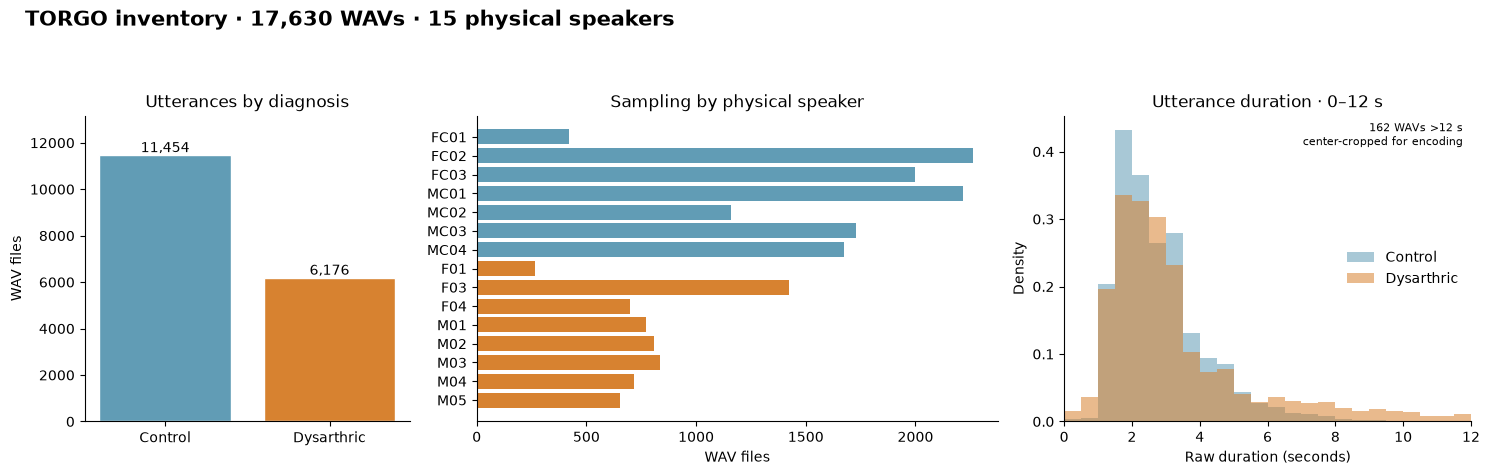

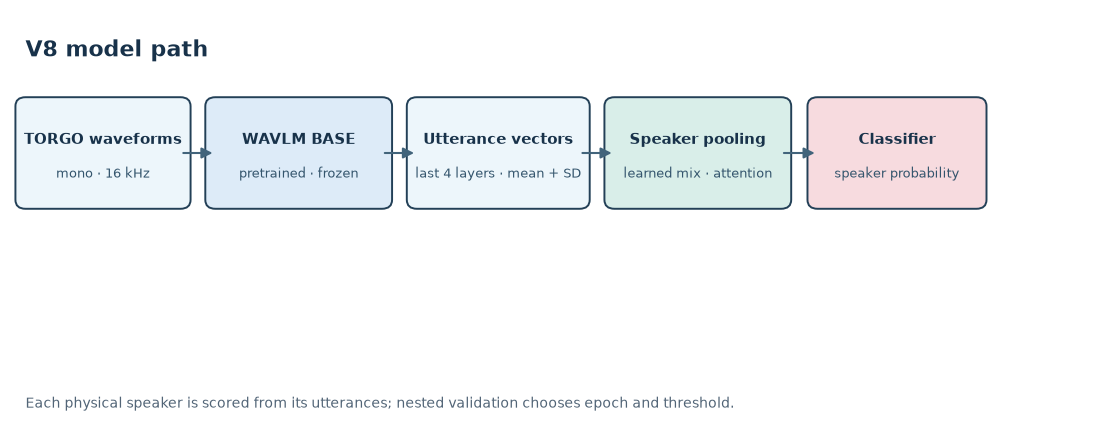

Pre-run figures saved under /Users/Noor/Documents/projects/dysarthia/v8/outputs/figures


In [80]:
overview_figure = plot_v8_dataset_overview(raw_inventory, OUT)
architecture_figure = plot_v8_architecture(OUT, config.encoder_name, config.use_fusion)
print(f"Pre-run figures saved under {OUT / 'figures'}")


## 3. Frozen encoder and V8 feature cache

Audio is resampled to mono 16 kHz, trimmed, normalized, and limited to 12 seconds. The encoder stays in evaluation mode; each accepted utterance yields the final four layer mean and standard-deviation vectors. WavLM is encoded one waveform at a time because this Torchaudio implementation rejects the padding mask used by variable-length batches. HuBERT uses length-aware batches. Engineered features are computed from the same V8 waveforms for the optional fusion arm.

Cache keys include raw file metadata, preprocessing choices, encoder identity, installed audio-library versions, and the pretrained weight hash. No V4–V7 feature, split, or model cache is read.

In [81]:
def choose_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _capture_rng_state(device: torch.device) -> dict[str, Any]:
    state: dict[str, Any] = {"cpu": torch.get_rng_state()}
    if device.type == "cuda":
        state["cuda"] = torch.cuda.get_rng_state_all()
    elif device.type == "mps":
        state["mps"] = torch.mps.get_rng_state()
    return state


def _restore_rng_state(state: dict[str, Any], device: torch.device) -> None:
    torch.set_rng_state(state["cpu"].cpu())
    if device.type == "cuda" and "cuda" in state:
        torch.cuda.set_rng_state_all([item.cpu() for item in state["cuda"]])
    elif device.type == "mps" and "mps" in state:
        torch.mps.set_rng_state(state["mps"].cpu())


def load_pretrained(config: Config, pretrained_dir: Path, device: torch.device):
    """Get weights in the v8 namespace and fingerprint the exact checkpoint."""
    bundle = getattr(torchaudio.pipelines, config.encoder_name)
    if int(bundle.sample_rate) != config.sample_rate:
        raise AssertionError("Pretrained model and waveform sample rates disagree")
    pretrained_dir.mkdir(parents=True, exist_ok=True)
    before = set(pretrained_dir.iterdir())
    model = bundle.get_model(dl_kwargs={"model_dir": str(pretrained_dir)})
    after = set(pretrained_dir.iterdir())
    weight_files = sorted(p for p in after if p.is_file() and p.suffix in {".pth", ".pt"})
    if len(weight_files) != 1:
        raise RuntimeError(f"Expected one v8-local pretrained weight file, found {weight_files}; new files={after-before}")
    weight_sha = _file_sha256(weight_files[0])
    model.eval().to(device)
    for param in model.parameters():
        param.requires_grad_(False)
    return model, weight_sha, weight_files[0]


def preprocess_waveform(path: Path, mic_type: str, config: Config) -> np.ndarray:
    audio, sr = sf.read(path, dtype="float32", always_2d=True)
    mono = audio.mean(axis=1)
    if sr != config.sample_rate:
        mono = librosa.resample(mono, orig_sr=sr, target_sr=config.sample_rate)
    mono, _ = librosa.effects.trim(mono, top_db=35 if mic_type == "head" else 25)
    if len(mono) == 0:
        mono = np.zeros(config.sample_rate // 10, dtype=np.float32)
    peak = float(np.max(np.abs(mono)))
    if peak > 0:
        mono = mono / peak
    if mic_type == "array":
        mono = np.where(np.abs(mono) < .01, 0.0, mono)
    max_samples = int(config.max_seconds * config.sample_rate)
    if len(mono) > max_samples:
        start = (len(mono) - max_samples) // 2
        mono = mono[start:start + max_samples]
    if len(mono) < 1024:
        mono = np.pad(mono, (0, 1024 - len(mono)))
    mono = np.asarray(mono, dtype=np.float32)
    if not np.isfinite(mono).all():
        raise ValueError("Non-finite waveform after preprocessing")
    return mono


def acoustic_features(audio: np.ndarray, sr: int) -> np.ndarray:
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    groups = [mfcc]
    for fn in (librosa.feature.rms, librosa.feature.zero_crossing_rate,
               librosa.feature.spectral_centroid, librosa.feature.spectral_bandwidth,
               librosa.feature.spectral_rolloff, librosa.feature.spectral_flatness):
        kwargs = {"y": audio}
        if fn in (librosa.feature.spectral_centroid, librosa.feature.spectral_bandwidth,
                  librosa.feature.spectral_rolloff):
            kwargs["sr"] = sr
        groups.append(fn(**kwargs))
    values = np.concatenate([np.concatenate([x.mean(axis=1), x.std(axis=1)]) for x in groups]
                            + [np.asarray([len(audio) / sr])]).astype(np.float32)
    if len(values) != len(ACOUSTIC_NAMES) or not np.isfinite(values).all():
        raise ValueError("Invalid engineered acoustic feature vector")
    return values


def masked_layer_statistics(layers: list[torch.Tensor], lengths: torch.Tensor,
                            selected_layers: int) -> np.ndarray:
    """Mean and SD of valid encoder frames for the last selected layers."""
    chosen = layers[-selected_layers:]
    if len(chosen) != selected_layers:
        raise ValueError("Encoder returned fewer layers than requested")
    output = []
    for layer in chosen:
        frame_count = layer.shape[1]
        mask = torch.arange(frame_count, device=layer.device)[None, :] < lengths[:, None]
        denom = mask.sum(dim=1).clamp_min(1).to(layer.dtype)[:, None]
        masked = layer * mask[..., None]
        mean = masked.sum(dim=1) / denom
        variance = (((layer - mean[:, None, :]) * mask[..., None]) ** 2).sum(dim=1) / denom
        output.append(torch.cat((mean, variance.clamp_min(0).sqrt()), dim=-1))
    stacked = torch.stack(output, dim=1).float().cpu().numpy()
    if not np.isfinite(stacked).all():
        raise ValueError("Non-finite pretrained speech embedding")
    return stacked


def _encode_batch(model: nn.Module, waveforms: list[np.ndarray], config: Config,
                  device: torch.device) -> np.ndarray:
    # Torchaudio 2.11's WavLM attention asserts that attention_mask is None.
    # Its Wav2Vec2Model builds that mask whenever lengths are supplied. Encode
    # each waveform unpadded so neither padded samples nor padded frames enter
    # the transformer or utterance statistics. HuBERT supports masked batches.
    if config.encoder_name == "WAVLM_BASE" and isinstance(model, torchaudio.models.Wav2Vec2Model):
        result = []
        with torch.inference_mode():
            for audio in waveforms:
                layers, _ = model.extract_features(torch.from_numpy(audio)[None, :].to(device))
                frame_lengths = torch.tensor([layers[-1].shape[1]], device=device)
                result.append(masked_layer_statistics(layers, frame_lengths, config.selected_layers)[0])
        return np.stack(result)
    lengths = torch.tensor([len(x) for x in waveforms], dtype=torch.long, device=device)
    padded = torch.zeros((len(waveforms), int(lengths.max())), dtype=torch.float32, device=device)
    for i, audio in enumerate(waveforms):
        padded[i, :len(audio)] = torch.from_numpy(audio).to(device)
    with torch.inference_mode():
        layers, frame_lengths = model.extract_features(padded, lengths=lengths)
        if frame_lengths is None:
            raise RuntimeError("Encoder did not return valid output lengths")
        return masked_layer_statistics(layers, frame_lengths, config.selected_layers)


def _feature_spec(config: Config, weight_sha: str) -> dict[str, Any]:
    return dict(pipeline_signature=PIPELINE_SIGNATURE, encoder=config.encoder_name,
                pretrained_weight_sha256=weight_sha, sample_rate=config.sample_rate,
                selected_layers=config.selected_layers, max_seconds=config.max_seconds,
                waveform_preprocessing="mono_resample_trim_normalize_array_gate_center_crop_v1",
                acoustic_recipe="mfcc13_rms_zcr_centroid_bandwidth_rolloff_flatness_duration_v1",
                torchaudio_version=torchaudio.__version__, librosa_version=librosa.__version__)


def _shard_path(shard_dir: Path, source_id: str, feature_hash: str) -> Path:
    key = _canonical_hash((source_id, feature_hash))
    return shard_dir / key[:2] / f"{key}.npz"


def extract_dataset_features(meta: pd.DataFrame, model: nn.Module, config: Config,
                             run_dir: Path, feature_spec: dict[str, Any],
                             device: torch.device) -> tuple[pd.DataFrame, np.ndarray, np.ndarray, pd.DataFrame]:
    """Resume per-WAV shards, then atomically publish a complete aggregate."""
    feature_hash = _canonical_hash(feature_spec)
    source_hash = source_signature(meta)
    aggregate = run_dir / "features"
    manifest_path = aggregate / "manifest.json"
    embedding_path = aggregate / "speech_embeddings.npy"
    acoustic_path = aggregate / "acoustic_features.npy"
    usable_path = aggregate / "usable_metadata.csv"
    if manifest_path.is_file():
        manifest = json.loads(manifest_path.read_text())
        if (manifest.get("complete") is True and manifest.get("source_signature") == source_hash
                and manifest.get("feature_signature") == feature_hash
                and all(p.is_file() for p in (embedding_path, acoustic_path, usable_path))):
            usable = pd.read_csv(usable_path)
            embedding = np.load(embedding_path, mmap_mode="r")
            acoustic = np.load(acoustic_path, mmap_mode="r")
            if len(usable) == len(embedding) == len(acoustic) == manifest["n_usable"]:
                return usable, embedding, acoustic, pd.DataFrame(manifest.get("extraction_errors", []))
    aggregate.mkdir(parents=True, exist_ok=True)
    shard_dir = run_dir / "embedding_shards"
    pending: list[tuple[int, pd.Series, Path]] = []
    errors: list[dict[str, str]] = []
    for i, row in meta.iterrows():
        shard = _shard_path(shard_dir, row.source_id, feature_hash)
        if shard.is_file():
            try:
                with np.load(shard) as saved:
                    if (str(saved["source_id"].item()) == row.source_id
                            and saved["embedding"].shape[0] == config.selected_layers
                            and saved["acoustic"].shape == (len(ACOUSTIC_NAMES),)
                            and np.isfinite(saved["embedding"]).all()
                            and np.isfinite(saved["acoustic"]).all()):
                        continue
            except Exception:
                pass
        pending.append((i, row, shard))
    print(f"V8 feature extraction: {len(meta)-len(pending)} cached shards, {len(pending)} new WAVs", flush=True)
    for offset in range(0, len(pending), config.encoder_batch_size):
        batch = pending[offset:offset + config.encoder_batch_size]
        ready: list[tuple[pd.Series, Path, np.ndarray, np.ndarray]] = []
        for _, row, shard in batch:
            try:
                audio = preprocess_waveform(Path(row.file_path), row.mic_type, config)
                acoustic = acoustic_features(audio, config.sample_rate)
                ready.append((row, shard, audio, acoustic))
            except Exception as exc:
                errors.append(dict(file_path=row.file_path, reason=f"preprocess_failed: {exc}"))
        if ready:
            try:
                embeddings = _encode_batch(model, [item[2] for item in ready], config, device)
            except RuntimeError as exc:
                if "out of memory" not in str(exc).lower() or len(ready) == 1:
                    raise
                if device.type == "cuda":
                    torch.cuda.empty_cache()
                embeddings = np.stack([_encode_batch(model, [item[2]], config, device)[0]
                                       for item in ready])
            for (row, shard, _, acoustic), embedding in zip(ready, embeddings):
                _atomic_npz(shard, embedding=embedding.astype(np.float32),
                            acoustic=acoustic, source_id=np.asarray(row.source_id))
        if (offset // config.encoder_batch_size + 1) % 100 == 0 or offset + len(batch) >= len(pending):
            print(f"V8 encoded {min(offset+len(batch), len(pending))}/{len(pending)} pending WAVs", flush=True)
    kept: list[int] = []
    for i, row in meta.iterrows():
        if _shard_path(shard_dir, row.source_id, feature_hash).is_file():
            kept.append(i)
        elif not any(e["file_path"] == row.file_path for e in errors):
            errors.append(dict(file_path=row.file_path, reason="embedding_shard_missing"))
    if not kept:
        raise RuntimeError("No V8 feature shards were produced")
    usable = meta.iloc[kept].reset_index(drop=True)
    first_shard = _shard_path(shard_dir, usable.iloc[0].source_id, feature_hash)
    with np.load(first_shard) as first:
        embed_shape = first["embedding"].shape
    embedding_temp = aggregate / "speech_embeddings.partial.npy"
    acoustic_temp = aggregate / "acoustic_features.partial.npy"
    embeddings = np.lib.format.open_memmap(embedding_temp, mode="w+", dtype="float32",
                                            shape=(len(usable),) + embed_shape)
    acoustics = np.lib.format.open_memmap(acoustic_temp, mode="w+", dtype="float32",
                                           shape=(len(usable), len(ACOUSTIC_NAMES)))
    for i, row in usable.iterrows():
        with np.load(_shard_path(shard_dir, row.source_id, feature_hash)) as shard:
            embeddings[i] = shard["embedding"]
            acoustics[i] = shard["acoustic"]
    embeddings.flush(); acoustics.flush()
    del embeddings, acoustics
    os.replace(embedding_temp, embedding_path)
    os.replace(acoustic_temp, acoustic_path)
    usable.to_csv(usable_path, index=False)
    _atomic_json(manifest_path, dict(complete=True, pipeline_signature=PIPELINE_SIGNATURE,
                                     source_signature=source_hash, feature_signature=feature_hash,
                                     feature_spec=feature_spec, n_usable=len(usable),
                                     embedding_shape=(len(usable),) + embed_shape,
                                     acoustic_names=ACOUSTIC_NAMES,
                                     extraction_errors=errors))
    return usable, np.load(embedding_path, mmap_mode="r"), np.load(acoustic_path, mmap_mode="r"), pd.DataFrame(errors)


## 4. Speaker-aware pooling and classifier

Each training bag samples up to 64 utterances from one physical speaker. A learned mixture combines the selected encoder layers; attention pools utterances into a speaker embedding. The optional arm concatenates standardized acoustic features. The acoustic scaler is fitted on training speakers only, with equal weight per speaker. At evaluation time, deterministic bags cover every utterance once and combine bag logits into one speaker probability.

In [82]:
def speaker_table(meta: pd.DataFrame) -> pd.DataFrame:
    table = (meta.groupby("physical_speaker_id", sort=True)
             .agg(label=("label", "first"), n_utterances=("label", "size"))
             .reset_index())
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("Conflicting labels within a physical speaker")
    return table


def grouped_speaker_splits(meta: pd.DataFrame, seed: int, folds: int):
    table = speaker_table(meta)
    if table.label.value_counts().min() < folds:
        raise ValueError(f"Need at least {folds} physical speakers per class")
    splitter = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=seed)
    seen: set[str] = set()
    for fold, (train, test) in enumerate(splitter.split(table, table.label, table.physical_speaker_id)):
        train_ids = set(table.iloc[train].physical_speaker_id)
        test_ids = set(table.iloc[test].physical_speaker_id)
        if train_ids & test_ids or seen & test_ids:
            raise AssertionError("Physical speaker appears in more than one partition")
        seen |= test_ids
        yield fold, train_ids, test_ids
    if seen != set(table.physical_speaker_id):
        raise AssertionError("Some physical speakers were omitted from grouped folds")


def fit_acoustic_scaler(meta: pd.DataFrame, acoustic: np.ndarray,
                        train_speakers: set[str]) -> tuple[np.ndarray, np.ndarray]:
    """Fit on training speakers with one total unit of weight per speaker."""
    if not train_speakers:
        raise ValueError("No speakers provided for scaler fit")
    if not train_speakers.issubset(set(meta.physical_speaker_id)):
        raise ValueError("Unknown speaker in training scaler fit")
    means, second_moments = [], []
    for speaker in sorted(train_speakers):
        values = np.asarray(acoustic[np.flatnonzero(meta.physical_speaker_id.eq(speaker))], dtype=np.float64)
        means.append(values.mean(axis=0))
        second_moments.append(np.square(values).mean(axis=0))
    mean = np.mean(means, axis=0)
    variance = np.maximum(np.mean(second_moments, axis=0) - mean ** 2, 1e-8)
    return mean.astype(np.float32), np.sqrt(variance).astype(np.float32)


class SpeakerAttentionClassifier(nn.Module):
    """Trainable layer mix and utterance attention conditioned on bag context."""

    def __init__(self, layers: int, embedding_dim: int, acoustic_dim: int, use_fusion: bool):
        super().__init__()
        self.use_fusion = use_fusion
        self.layer_logits = nn.Parameter(torch.zeros(layers))
        self.speech_proj = nn.Sequential(nn.Linear(embedding_dim, 128), nn.LayerNorm(128),
                                         nn.GELU(), nn.Dropout(.2))
        self.attention = nn.Sequential(nn.Linear(128 * 3, 64), nn.Tanh(), nn.Linear(64, 1))
        if use_fusion:
            self.acoustic_proj = nn.Sequential(nn.Linear(acoustic_dim * 2, 64),
                                                nn.LayerNorm(64), nn.GELU())
        self.classifier = nn.Sequential(nn.Linear(256 + (64 if use_fusion else 0), 64),
                                        nn.GELU(), nn.Dropout(.2), nn.Linear(64, 1))

    def forward(self, speech: torch.Tensor, acoustic: torch.Tensor | None = None,
                valid_mask: torch.Tensor | None = None,
                return_attention: bool = False):
        if speech.ndim != 3 or speech.shape[0] == 0:
            raise ValueError("Expected one nonempty speaker bag [utterance, layer, feature]")
        if valid_mask is None:
            valid_mask = torch.ones(speech.shape[0], dtype=torch.bool, device=speech.device)
        if valid_mask.sum() == 0:
            raise ValueError("Speaker bag has no valid utterances")
        mix = torch.softmax(self.layer_logits, dim=0)
        utterance = self.speech_proj((speech * mix[None, :, None]).sum(dim=1))
        mask_f = valid_mask.to(utterance.dtype)[:, None]
        context = (utterance * mask_f).sum(dim=0) / mask_f.sum()
        expanded = context[None, :].expand_as(utterance)
        score = self.attention(torch.cat((utterance, expanded, utterance * expanded), dim=-1)).squeeze(-1)
        score = score.masked_fill(~valid_mask, torch.finfo(score.dtype).min)
        weight = torch.softmax(score, dim=0)
        pooled = torch.cat(((utterance * weight[:, None]).sum(dim=0), context), dim=0)
        if self.use_fusion:
            if acoustic is None or acoustic.shape[0] != speech.shape[0]:
                raise ValueError("Fusion requires aligned utterance acoustic features")
            acoustic_mean = (acoustic * mask_f).sum(dim=0) / mask_f.sum()
            acoustic_weighted = (acoustic * weight[:, None]).sum(dim=0)
            pooled = torch.cat((pooled, self.acoustic_proj(torch.cat((acoustic_weighted, acoustic_mean)))), dim=0)
        logit = self.classifier(pooled).squeeze(-1)
        return (logit, weight) if return_attention else logit


class BagStore:
    def __init__(self, meta: pd.DataFrame, speech: np.ndarray, acoustic: np.ndarray,
                 scaler: tuple[np.ndarray, np.ndarray], device: torch.device):
        self.meta = meta
        self.speech = speech
        self.acoustic = acoustic
        self.mean, self.scale = scaler
        self.device = device
        self.indices = {str(sp): np.flatnonzero(meta.physical_speaker_id.eq(sp))
                        for sp in meta.physical_speaker_id.unique()}
        self.labels = {str(sp): int(meta.iloc[ix[0]].label) for sp, ix in self.indices.items()}

    def bag(self, speaker: str, *, maximum: int | None = None,
            rng: np.random.Generator | None = None,
            explicit_indices: np.ndarray | None = None) -> tuple[torch.Tensor, torch.Tensor]:
        ix = self.indices[speaker]
        if explicit_indices is not None:
            if not np.isin(explicit_indices, ix).all():
                raise AssertionError("Bag includes another speaker's utterance")
            ix = explicit_indices
        elif maximum is not None and len(ix) > maximum:
            if rng is None:
                raise ValueError("Random generator required for training bag sampling")
            ix = np.sort(rng.choice(ix, size=maximum, replace=False))
        speech = torch.from_numpy(np.array(self.speech[ix], dtype=np.float32, copy=True)).to(self.device)
        acoustic = np.array(self.acoustic[ix], dtype=np.float32, copy=True)
        acoustic = (acoustic - self.mean) / self.scale
        acoustic = torch.from_numpy(acoustic).to(self.device)
        return speech, acoustic


def _new_head(config: Config, speech: np.ndarray, acoustic: np.ndarray,
              use_fusion: bool, device: torch.device) -> SpeakerAttentionClassifier:
    return SpeakerAttentionClassifier(speech.shape[1], speech.shape[2], acoustic.shape[1],
                                      use_fusion).to(device)


def predict_speakers(model: SpeakerAttentionClassifier, store: BagStore,
                     speakers: set[str], bag_size: int = 64) -> pd.DataFrame:
    """Score every utterance once in deterministic train-sized speaker bags."""
    if bag_size < 1:
        raise ValueError("bag_size must be positive")
    model.eval()
    rows = []
    with torch.no_grad():
        for speaker in sorted(speakers):
            indices = store.indices[speaker]
            seed = int.from_bytes(hashlib.sha256(speaker.encode("utf-8")).digest()[:8], "big")
            order = np.random.default_rng(seed).permutation(indices)
            weighted_logit = 0.0
            n_bags = 0
            for start in range(0, len(order), bag_size):
                part = order[start:start + bag_size]
                speech, acoustic = store.bag(speaker, explicit_indices=part)
                weighted_logit += float(model(speech, acoustic).item()) * len(part)
                n_bags += 1
            p = float(expit(weighted_logit / len(indices)))
            rows.append(dict(physical_speaker_id=speaker, label=store.labels[speaker],
                             probability=p, n_utterances=len(indices), n_eval_bags=n_bags))
    return pd.DataFrame(rows)


def _head_training_signature(config: Config, run_signature: str, use_fusion: bool,
                             train_speakers: set[str], val_speakers: set[str] | None,
                             epochs: int | None, seed: int) -> str:
    return _canonical_hash(dict(run_signature=run_signature, use_fusion=use_fusion,
                                train_speakers=sorted(train_speakers),
                                val_speakers=sorted(val_speakers or []), epochs=epochs,
                                seed=seed, max_epochs=config.max_epochs,
                                max_utterances_per_bag=config.max_utterances_per_bag,
                                bags_per_epoch=config.bags_per_epoch,
                                learning_rate=config.learning_rate,
                                weight_decay=config.weight_decay, patience=config.patience))


In [83]:
speaker_summary = speaker_table(raw_inventory)
example_splits = list(grouped_speaker_splits(raw_inventory, seed=config.seeds[0], folds=config.outer_folds))
split_rows = []
for fold, train_ids, test_ids in example_splits:
    assert train_ids.isdisjoint(test_ids)
    split_rows.append({"outer_fold": fold, "n_train_speakers": len(train_ids),
                       "n_test_speakers": len(test_ids),
                       "held_out_speakers": ", ".join(sorted(test_ids))})
display(pd.DataFrame(split_rows))
print("Every physical speaker is held out exactly once in this seed:",
      sorted(sp for _, _, held_out in example_splits for sp in held_out)
      == sorted(speaker_summary.physical_speaker_id))


,outer_fold,n_train_speakers,n_test_speakers,held_out_speakers
0,0,12,3,"M03, M05, MC01"
1,1,12,3,"F01, MC02, MC04"
2,2,12,3,"F04, M02, MC03"
3,3,12,3,"FC01, FC02, M04"
4,4,12,3,"F03, FC03, M01"


Every physical speaker is held out exactly once in this seed: True


## 5. Nested training, threshold, and evaluation

Five outer folds are repeated for five seeds. Within each outer training partition, three grouped inner folds choose the head epoch and a speaker-level threshold targeting at least 0.90 sensitivity **on inner predictions**. The final head is retrained on all outer training speakers, then evaluated on held-out speakers. The outer predictions are pooled once per physical speaker and seed before calculating metrics. The 95% intervals resample physical speakers, using the same draw across seeds.

The small TORGO cohort limits precision. Repeated seeds are different partitions of the **same 15 people**; they do not constitute independent cohorts. An inner sensitivity target is not a guarantee of outer sensitivity.

In [84]:
def train_head(config: Config, meta: pd.DataFrame, speech: np.ndarray,
               acoustic: np.ndarray, train_speakers: set[str],
               val_speakers: set[str] | None, *, use_fusion: bool,
               seed: int, run_signature: str, checkpoint_dir: Path,
               device: torch.device, epochs: int | None = None) -> tuple[SpeakerAttentionClassifier, int, BagStore]:
    """Train only on physical train speakers; resume at the next epoch."""
    if val_speakers and train_speakers & val_speakers:
        raise AssertionError("Train/validation physical speaker overlap")
    signature = _head_training_signature(config, run_signature, use_fusion, train_speakers,
                                         val_speakers, epochs, seed)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    scaler_path = checkpoint_dir / "acoustic_scaler.npz"
    complete_path = checkpoint_dir / "complete.json"
    best_path = checkpoint_dir / "best.pt"
    latest_path = checkpoint_dir / "latest.pt"
    history_path = checkpoint_dir / "training_history.csv"
    history_columns = ("epoch", "train_logloss", "validation_logloss",
                       "validation_accuracy_0_5", "best_epoch",
                       "best_validation_logloss", "is_best", "history_status")

    def write_history(rows: list[dict[str, Any]]) -> None:
        _atomic_csv(history_path, pd.DataFrame(rows, columns=history_columns))

    def unavailable_history(last_epoch: int) -> list[dict[str, Any]]:
        # An older checkpoint cannot yield losses retrospectively.
        return [dict(epoch=i, train_logloss=None, validation_logloss=None,
                     validation_accuracy_0_5=None, best_epoch=None,
                     best_validation_logloss=None, is_best=None,
                     history_status="unavailable_prior_checkpoint")
                for i in range(1, last_epoch + 1)]

    scaler = fit_acoustic_scaler(meta, acoustic, train_speakers)
    store = BagStore(meta, speech, acoustic, scaler, device)
    if complete_path.is_file() and best_path.is_file() and scaler_path.is_file():
        complete = json.loads(complete_path.read_text())
        if complete.get("signature") == signature:
            if "history" in complete:
                # The completed checkpoint is authoritative if CSV was interrupted.
                write_history(complete["history"])
            elif latest_path.is_file():
                # A fold completed by the older runner has no historical losses.
                saved = torch.load(latest_path, map_location=device, weights_only=False)
                if saved.get("signature") == signature:
                    write_history(saved.get("history", unavailable_history(saved["epoch"])))
            set_seed(seed)
            model = _new_head(config, speech, acoustic, use_fusion, device)
            model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
            return model, int(complete["best_epoch"]), store
    set_seed(seed)
    model = _new_head(config, speech, acoustic, use_fusion, device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate,
                                  weight_decay=config.weight_decay)
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    bad_epochs = 0
    start_epoch = 1
    history: list[dict[str, Any]] = []
    if latest_path.is_file():
        saved = torch.load(latest_path, map_location=device, weights_only=False)
        if saved.get("signature") == signature:
            model.load_state_dict(saved["model"])
            optimizer.load_state_dict(saved["optimizer"])
            best_loss = saved["best_loss"]
            best_epoch = saved["best_epoch"]
            best_state = saved["best_state"]
            bad_epochs = saved["bad_epochs"]
            start_epoch = saved["epoch"] + 1
            if "history" in saved:
                history = saved["history"]
                if len(history) != saved["epoch"] or int(history[-1]["epoch"]) != saved["epoch"]:
                    raise RuntimeError(f"Checkpoint history is inconsistent: {latest_path}")
            else:
                # Earlier V8 checkpoints did not record losses. Show gaps, never
                # invent measurements, and continue from the saved model state.
                history = unavailable_history(saved["epoch"])
            write_history(history)
            _restore_rng_state(saved["rng_state"], device)
    limit = epochs if epochs is not None else config.max_epochs
    if start_epoch > limit and best_state is None:
        raise RuntimeError(f"Invalid checkpoint without best state: {latest_path}")
    train_ids = sorted(train_speakers)
    for epoch in range(start_epoch, limit + 1):
        model.train()
        epoch_train_losses: list[float] = []
        for repetition in range(config.bags_per_epoch):
            rng = np.random.default_rng(seed * 100_000_000 + epoch * 1_000 + repetition)
            optimizer.zero_grad(set_to_none=True)
            losses: dict[int, list[torch.Tensor]] = {0: [], 1: []}
            for speaker in train_ids:
                bag_speech, bag_acoustic = store.bag(
                    speaker, maximum=config.max_utterances_per_bag, rng=rng)
                label = store.labels[speaker]
                logit = model(bag_speech, bag_acoustic)
                target = torch.tensor(float(label), device=device)
                losses[label].append(F.binary_cross_entropy_with_logits(logit, target))
            if not losses[0] or not losses[1]:
                raise RuntimeError("Both diagnoses are required in each training partition")
            loss = .5 * torch.stack(losses[0]).mean() + .5 * torch.stack(losses[1]).mean()
            epoch_train_losses.append(float(loss.detach().item()))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        if val_speakers:
            val = predict_speakers(model, store, val_speakers, config.max_utterances_per_bag)
            p = np.clip(val.probability.to_numpy(), 1e-6, 1 - 1e-6)
            y = val.label.to_numpy()
            val_loss = float(np.mean(-(y * np.log(p) + (1-y) * np.log1p(-p))))
            val_accuracy = float(np.mean((p >= .5) == y))
        else:
            val_loss = float(epoch * -1)  # all requested final-fit epochs are kept
            val_accuracy = None
        is_best = val_loss < best_loss - 1e-6
        if is_best:
            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
        history.append(dict(epoch=epoch,
                            train_logloss=float(np.mean(epoch_train_losses)),
                            validation_logloss=val_loss if val_speakers else None,
                            validation_accuracy_0_5=val_accuracy,
                            best_epoch=best_epoch,
                            best_validation_logloss=best_loss if val_speakers else None,
                            is_best=is_best, history_status="logged"))
        # Save history inside the checkpoint first. If CSV writing is interrupted,
        # a resumed run repairs it from the authoritative checkpoint.
        _atomic_torch(latest_path, dict(signature=signature, epoch=epoch,
                                       model=model.state_dict(), optimizer=optimizer.state_dict(),
                                       best_state=best_state, best_loss=best_loss,
                                       best_epoch=best_epoch, bad_epochs=bad_epochs,
                                       rng_state=_capture_rng_state(device),
                                       history=history))
        write_history(history)
        if val_speakers and bad_epochs >= config.patience:
            break
    if best_state is None:
        raise RuntimeError("Head training did not produce a checkpoint")
    model.load_state_dict(best_state)
    _atomic_torch(best_path, best_state)
    _atomic_npz(scaler_path, mean=scaler[0], scale=scaler[1])
    _atomic_json(complete_path, dict(signature=signature, best_epoch=best_epoch,
                                     best_validation_logloss=best_loss if val_speakers else None,
                                     history=history, history_file=history_path.name,
                                     train_speakers=sorted(train_speakers),
                                     validation_speakers=sorted(val_speakers or []),
                                     use_fusion=use_fusion, frozen_encoder=True))
    return model, best_epoch, store


def select_threshold(validation: pd.DataFrame, min_sensitivity: float = .9) -> float:
    """Choose a speaker-level operating point using inner OOF predictions only."""
    if validation.physical_speaker_id.duplicated().any():
        raise AssertionError("Inner OOF must contain each speaker exactly once")
    y = validation.label.to_numpy(dtype=int)
    p = validation.probability.to_numpy(dtype=float)
    if set(y) != {0, 1}:
        raise ValueError("Both diagnoses required for threshold selection")
    candidates = np.r_[np.nextafter(p.min(), -np.inf), np.unique(p)]
    eligible = []
    for threshold in candidates:
        pred = p >= threshold
        sensitivity = pred[y == 1].mean()
        specificity = (~pred[y == 0]).mean()
        if sensitivity + 1e-12 >= min_sensitivity:
            eligible.append((specificity, threshold))
    return float(max(eligible)[1])


def speaker_metrics(predictions: pd.DataFrame) -> dict[str, float]:
    y = predictions.label.to_numpy(dtype=int)
    p = predictions.probability.to_numpy(dtype=float)
    pred = (p >= predictions.threshold.to_numpy(dtype=float)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    bins = np.minimum((p * 10).astype(int), 9)
    ece = sum((bins == b).mean() * abs(y[bins == b].mean() - p[bins == b].mean())
              for b in range(10) if (bins == b).any())
    return dict(n_speakers=len(y), Accuracy=float(accuracy_score(y, pred)),
                Balanced_Accuracy=float(balanced_accuracy_score(y, pred)) if both else float("nan"),
                Sensitivity=float(tp / (tp + fn)) if tp + fn else float("nan"),
                Specificity=float(tn / (tn + fp)) if tn + fp else float("nan"),
                F1_dysarthric=float(f1_score(y, pred, zero_division=0)),
                ROC_AUC=float(roc_auc_score(y, p)) if both else float("nan"),
                PR_AUC=float(average_precision_score(y, p)) if both else float("nan"),
                Brier=float(brier_score_loss(y, p)), ECE=float(ece))


def _run_outer_fold(config: Config, meta: pd.DataFrame, speech: np.ndarray,
                    acoustic: np.ndarray, *, seed: int, outer: int,
                    train_speakers: set[str], test_speakers: set[str],
                    use_fusion: bool, run_dir: Path, run_signature: str,
                    device: torch.device) -> pd.DataFrame:
    arm = "fusion" if use_fusion else "speech_only"
    fold_dir = run_dir / "folds" / arm / f"seed{seed}_outer{outer}"
    fold_dir.mkdir(parents=True, exist_ok=True)
    fold_signature = _canonical_hash(dict(run_signature=run_signature, arm=arm,
                                          seed=seed, outer_fold=outer,
                                          train_speakers=sorted(train_speakers),
                                          test_speakers=sorted(test_speakers)))
    prediction_path = fold_dir / "outer_speaker_predictions.csv"
    audit_path = fold_dir / "fold_audit.json"
    if audit_path.is_file() and prediction_path.is_file():
        audit = json.loads(audit_path.read_text())
        if audit.get("fold_signature") == fold_signature and audit.get("complete") is True:
            cached = pd.read_csv(prediction_path)
            if set(cached.physical_speaker_id) == test_speakers:
                return cached
    train_meta = meta[meta.physical_speaker_id.isin(train_speakers)].copy()
    inner_splits = list(grouped_speaker_splits(train_meta, seed + 731, config.inner_folds))
    inner_predictions = []
    inner_manifest = []
    selected_epochs = []
    for inner, inner_train, inner_val in inner_splits:
        if inner_train & inner_val or inner_train & test_speakers or inner_val & test_speakers:
            raise AssertionError("Nested split physical speaker leakage")
        model, best_epoch, store = train_head(
            config, meta, speech, acoustic, inner_train, inner_val,
            use_fusion=use_fusion, seed=seed * 1000 + outer * 10 + inner,
            run_signature=run_signature,
            checkpoint_dir=fold_dir / f"inner{inner}", device=device)
        validation = predict_speakers(model, store, inner_val, config.max_utterances_per_bag)
        validation["inner_fold"] = inner
        inner_predictions.append(validation)
        selected_epochs.append(best_epoch)
        inner_manifest.append(dict(inner_fold=inner,
                                   train_physical_speakers=sorted(inner_train),
                                   validation_physical_speakers=sorted(inner_val),
                                   best_epoch=best_epoch))
        print(f"V8 {arm} seed {seed} outer {outer} inner {inner}: best epoch {best_epoch}", flush=True)
    validation = pd.concat(inner_predictions, ignore_index=True)
    if set(validation.physical_speaker_id) != train_speakers or validation.physical_speaker_id.duplicated().any():
        raise AssertionError("Inner OOF does not cover each outer-train speaker exactly once")
    threshold = select_threshold(validation)
    final_epochs = max(1, int(np.median(selected_epochs).round()))
    final_model, _, final_store = train_head(
        config, meta, speech, acoustic, train_speakers, None,
        use_fusion=use_fusion, seed=seed * 1000 + outer * 10 + 9,
        run_signature=run_signature, checkpoint_dir=fold_dir / "final",
        device=device, epochs=final_epochs)
    test = predict_speakers(final_model, final_store, test_speakers, config.max_utterances_per_bag)
    test["seed"] = seed
    test["outer_fold"] = outer
    test["model_arm"] = arm
    test["threshold"] = threshold
    test["predicted_label"] = (test.probability >= threshold).astype(int)
    test["final_epochs"] = final_epochs
    _atomic_csv(fold_dir / "inner_oof_speaker_predictions.csv", validation)
    _atomic_csv(prediction_path, test)
    _atomic_json(audit_path, dict(complete=True, fold_signature=fold_signature,
                                  pipeline_signature=PIPELINE_SIGNATURE,
                                  seed=seed, outer_fold=outer, model_arm=arm,
                                  train_physical_speakers=sorted(train_speakers),
                                  test_physical_speakers=sorted(test_speakers),
                                  inner_folds=inner_manifest,
                                  threshold_source="inner_oof_train_speakers_only",
                                  min_inner_sensitivity=.9,
                                  selected_threshold=threshold,
                                  final_epochs=final_epochs,
                                  frozen_pretrained_encoder=True))
    print(f"V8 {arm} seed {seed} outer {outer}: held-out speakers {sorted(test_speakers)}", flush=True)
    return test


def _seed_metric_table(predictions: pd.DataFrame) -> pd.DataFrame:
    records = []
    for (arm, seed), group in predictions.groupby(["model_arm", "seed"], sort=True):
        if group.physical_speaker_id.duplicated().any():
            raise AssertionError("Each physical speaker must be held out once per seed")
        records.append(dict(model_arm=arm, seed=int(seed), **speaker_metrics(group)))
    return pd.DataFrame(records)


def _metric_summary(metric_table: pd.DataFrame) -> dict[str, Any]:
    metric_names = ["Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity",
                    "F1_dysarthric", "ROC_AUC", "PR_AUC", "Brier", "ECE"]
    result = {}
    for arm, group in metric_table.groupby("model_arm", sort=True):
        result[arm] = dict(n_seeds=len(group))
        for name in metric_names:
            values = group[name].dropna().to_numpy(dtype=float)
            result[arm][name] = dict(mean=float(values.mean()) if len(values) else None,
                                      sd=float(values.std(ddof=1)) if len(values) > 1 else None,
                                      estimable_seeds=len(values))
    return result


def speaker_cluster_bootstrap_ci(predictions: pd.DataFrame, *,
                                 resamples: int = 1000, seed: int = 2026) -> pd.DataFrame:
    """Resample physical speakers, using the same draw across all seeds."""
    if resamples < 1:
        raise ValueError("resamples must be positive")
    rng = np.random.default_rng(seed)
    records = []
    metric_names = ("ROC_AUC", "PR_AUC", "Balanced_Accuracy", "Sensitivity",
                    "Specificity", "Brier")
    for arm, arm_frame in predictions.groupby("model_arm", sort=True):
        identity = arm_frame[["physical_speaker_id", "label"]].drop_duplicates()
        if identity.physical_speaker_id.duplicated().any() or set(identity.label) != {0, 1}:
            raise AssertionError("Inconsistent physical speaker labels for bootstrap")
        by_seed = {int(s): frame.set_index("physical_speaker_id", drop=False)
                   for s, frame in arm_frame.groupby("seed")}
        expected_ids = set(identity.physical_speaker_id)
        if any(set(frame.index) != expected_ids for frame in by_seed.values()):
            raise AssertionError("All seeds must contain the same physical speakers")
        classes = {label: identity.loc[identity.label.eq(label), "physical_speaker_id"].to_numpy()
                   for label in (0, 1)}
        distributions = {name: [] for name in metric_names}
        for _ in range(resamples):
            drawn = np.concatenate([rng.choice(ids, size=len(ids), replace=True)
                                    for ids in classes.values()])
            per_seed = [speaker_metrics(frame.loc[drawn].reset_index(drop=True))
                        for frame in by_seed.values()]
            for name in metric_names:
                distributions[name].append(float(np.mean([item[name] for item in per_seed])))
        for name, values in distributions.items():
            low, high = np.percentile(values, [2.5, 97.5])
            records.append(dict(model_arm=arm, metric=name, lower_95=float(low),
                                upper_95=float(high), n_resamples=resamples,
                                resampling_unit="physical_speaker",
                                stratified_by_diagnosis=True,
                                same_speaker_draw_across_seeds=True))
    return pd.DataFrame(records)


In [85]:
def run_all(config: Config | None = None) -> dict[str, Any]:
    """Fresh/resumable V8 Run All; never imports a previous version's cache."""
    config = config or Config()
    config.validate()
    OUT.mkdir(parents=True, exist_ok=True)
    root = resolve_dataset_root(config)
    meta, inventory_issues = inventory_dataset(root)
    device = choose_device()
    print(f"V8: {len(meta)} raw WAVs passed inventory; {len(inventory_issues)} excluded; device={device}", flush=True)
    model, weight_sha, weight_path = load_pretrained(
        config, CACHE_ROOT / "pretrained" / config.encoder_name, device)
    feature_spec = _feature_spec(config, weight_sha)
    run_signature = _canonical_hash(dict(pipeline_signature=PIPELINE_SIGNATURE,
                                         config=asdict(config), source_signature=source_signature(meta),
                                         feature_spec=feature_spec))
    run_dir = CACHE_ROOT / f"run_{run_signature[:16]}"
    run_dir.mkdir(parents=True, exist_ok=True)
    _atomic_csv(run_dir / "raw_inventory.csv", meta)
    _atomic_json(run_dir / "run_manifest.json", dict(
        pipeline_signature=PIPELINE_SIGNATURE, run_signature=run_signature,
        config=asdict(config), dataset_root=str(root),
        raw_source_signature=source_signature(meta), feature_spec=feature_spec,
        pretrained_weight_path=str(weight_path), pretrained_weight_sha256=weight_sha,
        pretrained_encoder_frozen=True, external_dataset_used=False,
        previous_version_cache_used=False))
    meta, speech, acoustic, extraction_issues = extract_dataset_features(
        meta, model, config, run_dir, feature_spec, device)
    # The encoder is finished after feature extraction; the head uses only v8 arrays.
    del model
    issues = pd.concat((inventory_issues, extraction_issues), ignore_index=True)
    _atomic_csv(run_dir / "excluded_audio.csv", issues)
    if set(meta.physical_speaker_id) != OFFICIAL_TORGO_ROSTER:
        raise AssertionError("Usable V8 audio no longer covers the complete TORGO roster")
    arms = [False, True] if config.use_fusion else [False]
    fold_predictions = []
    for use_fusion in arms:
        for seed in config.seeds:
            outer_splits = list(grouped_speaker_splits(meta, seed, config.outer_folds))
            for outer, train_speakers, test_speakers in outer_splits:
                fold_predictions.append(_run_outer_fold(
                    config, meta, speech, acoustic, seed=seed, outer=outer,
                    train_speakers=train_speakers, test_speakers=test_speakers,
                    use_fusion=use_fusion, run_dir=run_dir,
                    run_signature=run_signature, device=device))
    predictions = pd.concat(fold_predictions, ignore_index=True)
    speaker_set = set(meta.physical_speaker_id)
    for (_, _), group in predictions.groupby(["model_arm", "seed"]):
        if set(group.physical_speaker_id) != speaker_set or len(group) != len(speaker_set):
            raise AssertionError("Pooled OOF is missing or duplicating physical speakers")
    metrics = _seed_metric_table(predictions)
    cluster_ci = speaker_cluster_bootstrap_ci(predictions)
    summary = dict(pipeline_signature=PIPELINE_SIGNATURE, run_signature=run_signature,
                   output_dir=str(run_dir), encoder_name=config.encoder_name,
                   frozen_pretrained_encoder=True, trainable_layer_mix=True,
                   model_arms=["speech_only", "fusion"] if config.use_fusion else ["speech_only"],
                   n_usable_utterances=len(meta), n_excluded_audio=len(issues),
                   n_physical_speakers=len(speaker_set), n_seeds=len(config.seeds),
                   evaluation_unit="physical_speaker",
                   threshold_source="nested_inner_speaker_oof",
                   external_dataset_used=False, previous_version_cache_used=False,
                   per_arm=_metric_summary(metrics),
                   speaker_cluster_95_ci=cluster_ci.to_dict("records"))
    _atomic_csv(run_dir / "v8_speaker_oof_predictions.csv", predictions)
    _atomic_csv(run_dir / "v8_per_seed_speaker_metrics.csv", metrics)
    _atomic_csv(run_dir / "v8_speaker_cluster_ci.csv", cluster_ci)
    _atomic_json(run_dir / "v8_summary.json", summary)
    _atomic_json(OUT / "v8_latest_run.json", dict(run_signature=run_signature,
                                                   output_dir=str(run_dir),
                                                   summary_file=str(run_dir / "v8_summary.json")))
    print(json.dumps(summary, indent=2), flush=True)
    return summary


## 6. Run the experiment

**Run All executes the cell below.** Extraction can take a long time. If interrupted, rerunning this notebook reuses only matching V8 artifacts and continues remaining work. The final result tables and charts below require this cell to finish. No performance value is inferred from a partial run.

In [86]:
result = run_all(config)
run_dir = Path(result["output_dir"])
print(f"Completed V8 run: {run_dir}")


V8: 17630 raw WAVs passed inventory; 5 excluded; device=mps
{
  "pipeline_signature": "v8_frozen_ssl_speaker_bag_1",
  "run_signature": "2058b417224f62906b365541814f27dec7df7b5f3efa7a9917c75080713c9758",
  "output_dir": "/Users/Noor/Documents/projects/dysarthia/v8/outputs/cache/dysarthria_detection_v8/run_2058b417224f6290",
  "encoder_name": "WAVLM_BASE",
  "frozen_pretrained_encoder": true,
  "trainable_layer_mix": true,
  "model_arms": [
    "speech_only"
  ],
  "n_usable_utterances": 17630,
  "n_excluded_audio": 5,
  "n_physical_speakers": 15,
  "n_seeds": 5,
  "evaluation_unit": "physical_speaker",
  "threshold_source": "nested_inner_speaker_oof",
  "external_dataset_used": false,
  "previous_version_cache_used": false,
  "per_arm": {
    "speech_only": {
      "n_seeds": 5,
      "Accuracy": {
        "mean": 0.8533333333333333,
        "sd": 0.08692269873603534,
        "estimable_seeds": 5
      },
      "Balanced_Accuracy": {
        "mean": 0.8535714285714286,
        "sd": 0.

## 7. Held-out speaker results

The tables below load the outputs written by the completed run. The main metric table reports one value per seed. Its mean and standard deviation describe partition/training variation; cluster intervals address sampling uncertainty across physical speakers. All ROC and precision–recall curves use held-out speaker probabilities.

In [87]:
predictions = pd.read_csv(run_dir / "v8_speaker_oof_predictions.csv")
metrics = pd.read_csv(run_dir / "v8_per_seed_speaker_metrics.csv")
cluster_ci = pd.read_csv(run_dir / "v8_speaker_cluster_ci.csv")
assert predictions.groupby(["model_arm", "seed"]).physical_speaker_id.nunique().eq(result["n_physical_speakers"]).all()
print("Held-out predictions:", len(predictions), "speaker × seed × arm rows")
display(metrics.round(3))
display(cluster_ci[["model_arm", "metric", "lower_95", "upper_95"]].round(3))


Held-out predictions: 75 speaker × seed × arm rows


,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE
0,speech_only,42,15,0.867,0.866,0.875,0.857,0.875,0.821,0.841,0.185,0.312
1,speech_only,43,15,0.933,0.929,1.000,0.857,0.941,0.929,0.932,0.131,0.183
2,speech_only,44,15,0.933,0.929,1.000,0.857,0.941,0.911,0.921,0.112,0.153
3,speech_only,45,15,0.800,0.804,0.750,0.857,0.800,0.964,0.975,0.068,0.113
4,speech_only,46,15,0.733,0.741,0.625,0.857,0.714,0.625,0.749,0.303,0.389


,model_arm,metric,lower_95,upper_95
0,speech_only,ROC_AUC,0.679,0.979
1,speech_only,PR_AUC,0.771,0.988
2,speech_only,Balanced_Accuracy,0.714,0.971
3,speech_only,Sensitivity,0.699,1.000
4,speech_only,Specificity,0.629,1.000
5,speech_only,Brier,0.060,0.279


In [88]:
def plot_v8_seed_curves(predictions, run_dir, model_arm="speech_only"):
    """Held-out speaker ROC and precision–recall, one curve per seed."""
    frame = _v8_arm_frame(predictions, model_arm)
    fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(12.5, 5.2))
    cmap = plt.get_cmap("viridis")
    seeds = sorted(frame.seed.unique())
    for i, seed in enumerate(seeds):
        group = frame.loc[frame.seed.eq(seed)]
        y = group.label.to_numpy(dtype=int)
        p = group.probability.to_numpy(dtype=float)
        if len(np.unique(y)) < 2:
            continue
        color = cmap(.15 + .75 * i/max(1, len(seeds)-1))
        fpr, tpr, _ = roc_curve(y, p)
        precision, recall, _ = precision_recall_curve(y, p)
        roc_ax.plot(fpr, tpr, lw=1.8, color=color,
                    label=f"Seed {seed} · AUC {auc(fpr,tpr):.2f}")
        pr_ax.plot(recall, precision, lw=1.8, color=color,
                   label=f"Seed {seed} · AP {average_precision_score(y,p):.2f}")
    prevalence = frame.drop_duplicates("physical_speaker_id").label.mean()
    roc_ax.plot([0, 1], [0, 1], "--", color="#9AA5AF", lw=1)
    pr_ax.axhline(prevalence, ls="--", color="#9AA5AF", lw=1,
                  label=f"Prevalence {prevalence:.2f}")
    for ax, title, xlab, ylab in [(roc_ax, "ROC", "False positive rate", "True positive rate"),
                                  (pr_ax, "Precision–recall", "Recall", "Precision")]:
        ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel=xlab, ylabel=ylab, title=title)
        ax.grid(alpha=.18)
        ax.legend(loc="lower right" if ax is roc_ax else "lower left", fontsize=8, frameon=False)
    fig.suptitle(f"Held-out physical-speaker curves · {model_arm.replace('_', ' ')}",
                 fontsize=15, fontweight="bold")
    fig.tight_layout()
    return _v8_finish(fig, run_dir, f"v8_{model_arm}_seed_roc_pr")


def plot_v8_calibration(predictions, run_dir, model_arm="speech_only", n_bins=5):
    """Reliability after averaging each speaker's held-out probability across seeds."""
    frame = _v8_arm_frame(predictions, model_arm)
    speaker = (frame.groupby("physical_speaker_id", as_index=False)
               .agg(label=("label", "first"), probability=("probability", "mean")))
    if speaker.label.nunique() < 2:
        raise ValueError("Calibration plot requires both diagnoses")
    ordered = speaker.sort_values("probability").reset_index(drop=True)
    chunks = [ordered.iloc[index] for index in
              np.array_split(np.arange(len(ordered)),
                             min(n_bins, max(1, len(ordered)//2))) if len(index)]
    points = pd.DataFrame([{"confidence": part.probability.mean(),
                            "observed": part.label.mean(), "n": len(part)}
                           for part in chunks])
    fig, (ax, hist_ax) = plt.subplots(1, 2, figsize=(11.7, 4.8),
                                     gridspec_kw={"width_ratios": [1.1, 1]})
    ax.plot([0, 1], [0, 1], "--", color="#87949E", label="Ideal")
    ax.plot(points.confidence, points.observed, color=V8_COLORS.get(model_arm, "#176B87"),
            marker="o", lw=1.7)
    for row in points.itertuples():
        ax.annotate(f"n={row.n}", (row.confidence, row.observed),
                    xytext=(5, 5), textcoords="offset points", fontsize=8)
    ax.set(xlim=(-.03, 1.03), ylim=(-.03, 1.03),
           xlabel="Mean held-out probability across seeds",
           ylabel="Observed dysarthria fraction", title="Reliability bins")
    ax.grid(alpha=.18)
    hist_ax.hist(speaker.loc[speaker.label.eq(0), "probability"], bins=np.linspace(0, 1, 11),
                 alpha=.65, color="#619CB5", label="Control")
    hist_ax.hist(speaker.loc[speaker.label.eq(1), "probability"], bins=np.linspace(0, 1, 11),
                 alpha=.65, color="#D78230", label="Dysarthric")
    hist_ax.set(xlim=(0, 1), xlabel="Mean held-out probability across seeds",
                ylabel="Physical speakers", title="Probability distribution")
    hist_ax.legend(frameon=False)
    fig.suptitle(f"Speaker calibration · {model_arm.replace('_', ' ')} · n={len(speaker)} speakers",
                 fontsize=14, fontweight="bold")
    fig.text(.5, .005, "Exploratory calibration: repeated seeds are averaged per speaker; bins are small.",
             ha="center", fontsize=9, color="#596977")
    fig.tight_layout(rect=(0, .04, 1, .94))
    return _v8_finish(fig, run_dir, f"v8_{model_arm}_calibration")


def plot_v8_confusion(predictions, run_dir, model_arm="speech_only"):
    """Mean held-out confusion counts per seed, preserving the speaker unit."""
    frame = _v8_arm_frame(predictions, model_arm)
    if "predicted_label" not in frame:
        _v8_check_columns(frame, ["threshold"], "predictions")
        frame["predicted_label"] = frame.probability.ge(frame.threshold).astype(int)
    matrices = np.stack([confusion_matrix(group.label, group.predicted_label, labels=[0, 1])
                         for _, group in frame.groupby("seed", sort=True)])
    mean = matrices.mean(axis=0)
    sd = matrices.std(axis=0, ddof=1) if len(matrices) > 1 else np.zeros((2, 2))
    labels = np.array([[f"{mean[r,c]:.1f}\n±{sd[r,c]:.1f}" for c in range(2)] for r in range(2)])
    fig, ax = plt.subplots(figsize=(5.7, 4.9))
    sns.heatmap(mean, annot=labels, fmt="", cmap="Blues", cbar=False,
                xticklabels=[V8_CLASS[0], V8_CLASS[1]],
                yticklabels=[V8_CLASS[0], V8_CLASS[1]],
                linewidths=2, linecolor="white", ax=ax,
                vmin=0, vmax=max(1, mean.max()))
    ax.set(xlabel="Predicted", ylabel="True",
           title=f"{model_arm.replace('_', ' ').title()} · mean speaker count per seed")
    ax.tick_params(axis="y", rotation=0)
    fig.text(.5, .02, f"Cells show mean ± SD over {len(matrices)} seed(s); threshold selected in inner validation.",
             ha="center", fontsize=9, color="#596977")
    fig.tight_layout(rect=(0, .06, 1, 1))
    return _v8_finish(fig, run_dir, f"v8_{model_arm}_confusion")


def plot_v8_speaker_heatmap(predictions, run_dir, model_arm="speech_only"):
    """Held-out probability per physical speaker and seed; × marks errors."""
    frame = _v8_arm_frame(predictions, model_arm)
    if "predicted_label" not in frame:
        _v8_check_columns(frame, ["threshold"], "predictions")
        frame["predicted_label"] = frame.probability.ge(frame.threshold).astype(int)
    identity = frame[["physical_speaker_id", "label"]].drop_duplicates()
    if identity.duplicated("physical_speaker_id").any():
        raise ValueError("Speaker diagnosis differs across seeds")
    ids = identity.sort_values(["label", "physical_speaker_id"]).physical_speaker_id.tolist()
    probability = frame.pivot(index="physical_speaker_id", columns="seed", values="probability").loc[ids]
    wrong = (frame.assign(error=frame.predicted_label.ne(frame.label))
                  .pivot(index="physical_speaker_id", columns="seed", values="error")
                  .reindex(index=ids, columns=probability.columns))
    n_controls = int(identity.label.eq(0).sum())
    height = max(5.3, .35*len(ids)+1.8)
    fig, ax = plt.subplots(figsize=(max(6.0, 1.05*len(probability.columns)+2.5), height))
    sns.heatmap(probability, cmap="RdYlBu_r", vmin=0, vmax=1, ax=ax,
                annot=True, fmt=".2f", annot_kws={"fontsize": 8},
                linewidths=.5, linecolor="white",
                cbar_kws={"label": "Held-out P(dysarthria)"})
    ax.hlines(n_controls, *ax.get_xlim(), colors="#1D2B35", linewidth=2)
    for row, col in np.argwhere(wrong.fillna(False).to_numpy(dtype=bool)):
        ax.text(col+.79, row+.23, "×", color="black", fontweight="bold",
                fontsize=11, ha="center", va="center")
    ax.set(xlabel="Seed", ylabel="Physical speaker",
           title=f"Held-out speaker probabilities · {model_arm.replace('_', ' ')}")
    ax.tick_params(axis="x", rotation=0)
    fig.text(.5, .005,
             "Controls above divider; dysarthric speakers below. × indicates an error at that fold's inner-selected threshold.",
             ha="center", fontsize=9, color="#596977")
    fig.tight_layout(rect=(0, .035, 1, 1))
    return _v8_finish(fig, run_dir, f"v8_{model_arm}_speaker_heatmap")


def plot_v8_model_metrics(metrics, ci, run_dir):
    """Mean over seeds, seed dots, and physical-speaker bootstrap 95% CI."""
    _v8_check_columns(metrics, ["model_arm", "seed", "ROC_AUC", "PR_AUC",
                                "Balanced_Accuracy", "Sensitivity", "Specificity", "Brier"],
                      "metrics")
    _v8_check_columns(ci, ["model_arm", "metric", "lower_95", "upper_95"], "ci")
    arms = sorted(metrics.model_arm.unique(), key=lambda a: (a != "speech_only", a))
    names = ["ROC_AUC", "PR_AUC", "Balanced_Accuracy", "Sensitivity", "Specificity"]
    pretty = ["ROC AUC", "PR AUC", "Balanced acc.", "Sensitivity", "Specificity"]
    fig, (ax, brier_ax) = plt.subplots(1, 2, figsize=(14, 5),
                                      gridspec_kw={"width_ratios": [2.4, 1]})
    offsets = np.linspace(-.16, .16, len(arms)) if len(arms) > 1 else [0.]
    width = .29 if len(arms) > 1 else .38
    for arm, offset in zip(arms, offsets):
        color = V8_COLORS.get(arm, "#555E69")
        subset = metrics.loc[metrics.model_arm.eq(arm)]
        for i, name in enumerate(names):
            values = pd.to_numeric(subset[name], errors="coerce").dropna()
            if values.empty:
                continue
            point = float(values.mean())
            ci_row = ci.loc[ci.model_arm.eq(arm) & ci.metric.eq(name)]
            ax.scatter(np.full(len(values), i+offset), values, color=color,
                       s=19, alpha=.22, zorder=2)
            if not ci_row.empty:
                low, high = ci_row.iloc[0][["lower_95", "upper_95"]].astype(float)
                ax.errorbar(i+offset, point,
                            yerr=[[max(0, point-low)], [max(0, high-point)]],
                            fmt="o", color=color, capsize=4, lw=2, markersize=7,
                            zorder=4)
            else:
                ax.plot(i+offset, point, "o", color=color, markersize=7)
        vals = pd.to_numeric(subset.Brier, errors="coerce").dropna()
        if len(vals):
            point = float(vals.mean())
            ci_row = ci.loc[ci.model_arm.eq(arm) & ci.metric.eq("Brier")]
            brier_ax.scatter(np.full(len(vals), offset), vals, color=color,
                             s=19, alpha=.22, zorder=2)
            if not ci_row.empty:
                low, high = ci_row.iloc[0][["lower_95", "upper_95"]].astype(float)
                brier_ax.errorbar(offset, point,
                                  yerr=[[max(0, point-low)], [max(0, high-point)]],
                                  fmt="o", color=color, capsize=4, lw=2,
                                  markersize=7, zorder=4)
            else:
                brier_ax.plot(offset, point, "o", color=color, markersize=7)
        ax.plot([], [], "o", color=color, label=arm.replace("_", " "))
    ax.set_xticks(range(len(names)), pretty, rotation=22, ha="right")
    ax.set(ylabel="Score (higher is better)", ylim=(0, 1.06),
           title="Discrimination and classification")
    brier_ax.set(xlim=(-.5, .5), xticks=[0], xticklabels=["Brier"],
                 ylabel="Score (lower is better)", title="Probability error")
    for panel in (ax, brier_ax):
        panel.grid(axis="y", alpha=.2)
    ax.legend(frameon=False, loc="lower left")
    fig.suptitle("Speaker-level performance · seed means and speaker bootstrap 95% intervals",
                 fontsize=14, fontweight="bold")
    fig.text(.5, .005, "Faint dots are seed scores on the same speaker cohort; intervals resample physical speakers.",
             ha="center", fontsize=9, color="#596977")
    fig.tight_layout(rect=(0, .045, 1, .93))
    return _v8_finish(fig, run_dir, "v8_model_metrics")


def plot_v8_training_convergence(history, run_dir):
    """Epoch curves from notebook-captured train/validation history.

    Required columns: model_arm, seed, outer_fold, inner_fold, epoch, and either
    train_loss/val_loss or train_logloss/validation_logloss. Each curve is one
    nested inner fit; bold curves show available-fit
    means at that epoch. This function never invents unavailable loss history.
    """
    if history is None or len(history) == 0:
        print("Epoch loss history was not recorded; training-convergence plot skipped.")
        return None
    hist = history.rename(columns={"train_logloss": "train_loss",
                                   "validation_logloss": "val_loss"}).copy()
    required = ["model_arm", "seed", "outer_fold", "inner_fold", "epoch",
                "train_loss", "val_loss"]
    _v8_check_columns(hist, required, "training history")
    hist["epoch"] = pd.to_numeric(hist.epoch, errors="coerce")
    for name in ("train_loss", "val_loss"):
        hist[name] = pd.to_numeric(hist[name], errors="coerce")
    hist = hist.dropna(subset=["epoch", "train_loss", "val_loss"])
    if hist.empty:
        print("No numeric epoch loss history; training-convergence plot skipped.")
        return None
    arms = sorted(hist.model_arm.unique(), key=lambda a: (a != "speech_only", a))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    group_cols = ["model_arm", "seed", "outer_fold", "inner_fold"]
    for arm in arms:
        color = V8_COLORS.get(arm, "#555E69")
        subset = hist.loc[hist.model_arm.eq(arm)]
        for _, fit in subset.groupby(group_cols):
            for ax, col in zip(axes[:2], ("train_loss", "val_loss")):
                ax.plot(fit.epoch, fit[col], color=color, alpha=.08, lw=.9)
        mean = subset.groupby("epoch", as_index=False)[["train_loss", "val_loss"]].mean()
        active = subset.groupby("epoch")[group_cols[1:]].apply(
            lambda x: len(x.drop_duplicates())).reset_index(name="n_fits")
        for ax, col in zip(axes[:2], ("train_loss", "val_loss")):
            ax.plot(mean.epoch, mean[col], color=color, lw=2.5,
                    label=arm.replace("_", " "))
        axes[2].plot(active.epoch, active.n_fits, color=color, lw=2,
                     label=arm.replace("_", " "))
    for ax, title, ylabel in [(axes[0], "Train loss", "Binary cross-entropy"),
                              (axes[1], "Inner-validation loss", "Speaker log loss"),
                              (axes[2], "Fits still active", "Nested inner fits")]:
        ax.set(xlabel="Epoch", ylabel=ylabel, title=title)
        ax.grid(alpha=.18)
    axes[1].legend(frameon=False)
    fig.suptitle("Head training convergence · thin lines are individual inner fits",
                 fontsize=14, fontweight="bold")
    fig.text(.5, .005,
             "Later-epoch means include only fits still training; compare with the active-fit panel.",
             ha="center", fontsize=9, color="#596977")
    fig.tight_layout(rect=(0, .04, 1, .93))
    return _v8_finish(fig, run_dir, "v8_training_convergence")


def plot_v8_epoch_selection(audits, run_dir):
    """Fallback diagnostic when only fold audits, not epoch histories, exist.

    audits is a DataFrame with model_arm and best_epoch, one row per inner fit.
    This is explicitly an epoch-selection distribution, not convergence.
    """
    if audits is None or len(audits) == 0:
        print("No inner-fold audit epochs available; epoch-selection plot skipped.")
        return None
    _v8_check_columns(audits, ["model_arm", "best_epoch"], "audits")
    fig, ax = plt.subplots(figsize=(8, 4.2))
    arms = sorted(audits.model_arm.unique(), key=lambda a: (a != "speech_only", a))
    data = [audits.loc[audits.model_arm.eq(arm), "best_epoch"].dropna().astype(float)
            for arm in arms]
    ax.boxplot(data, tick_labels=[arm.replace("_", " ") for arm in arms],
               patch_artist=True, boxprops={"facecolor": "#DDEBF8"},
               medianprops={"color": "#D78230", "linewidth": 2})
    ax.set(ylabel="Selected best epoch", title="Inner-fold epoch selection")
    ax.grid(axis="y", alpha=.2)
    fig.tight_layout()
    return _v8_finish(fig, run_dir, "v8_epoch_selection")


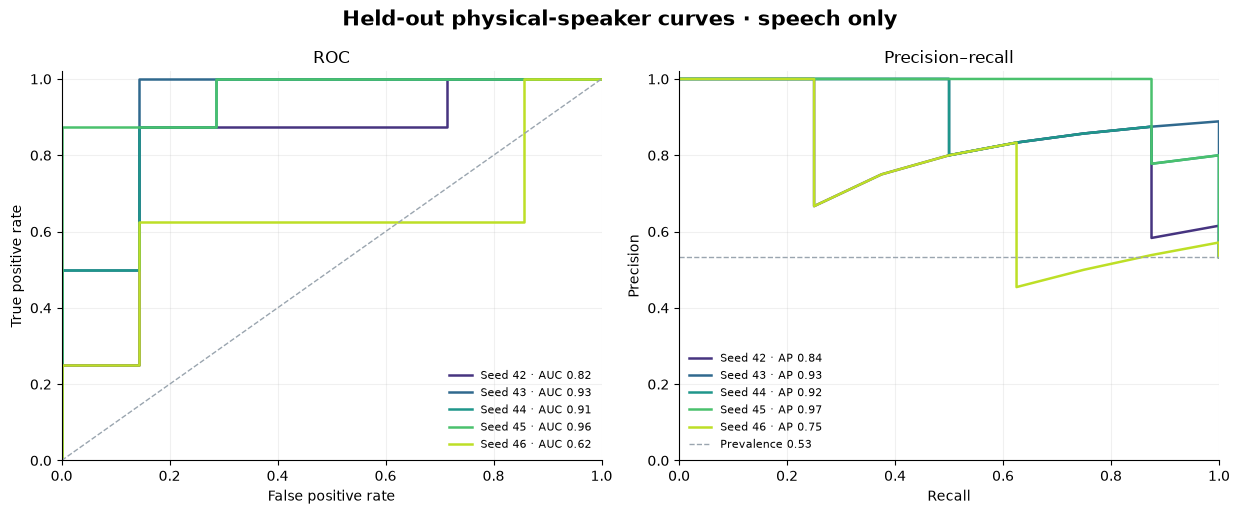

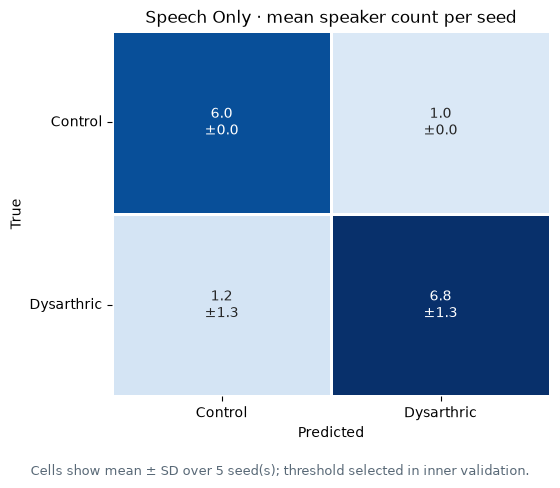

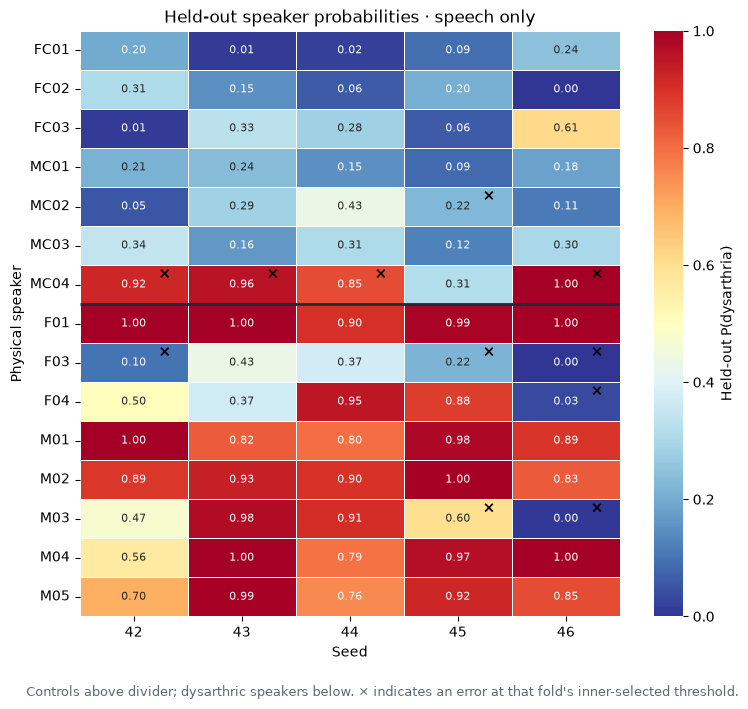

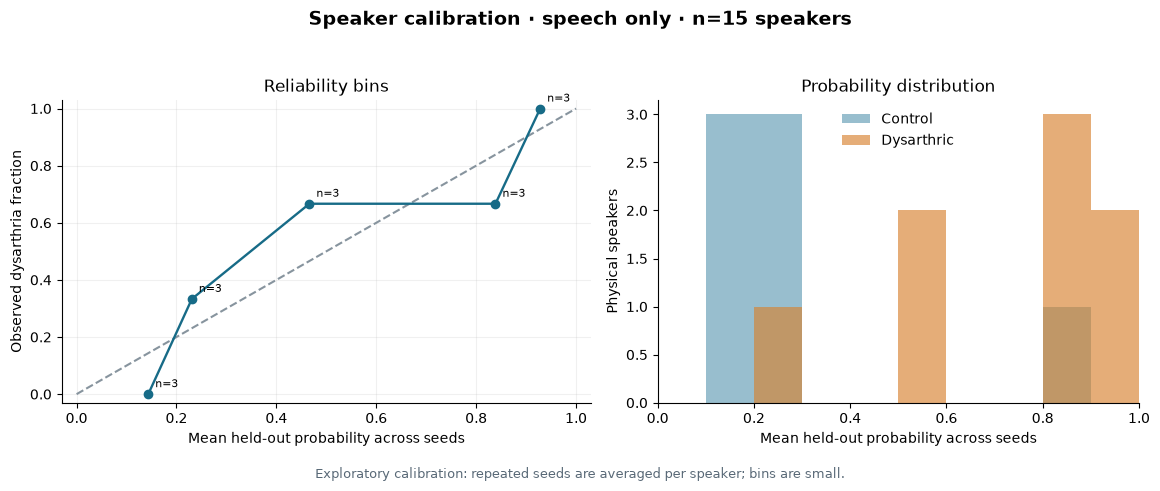

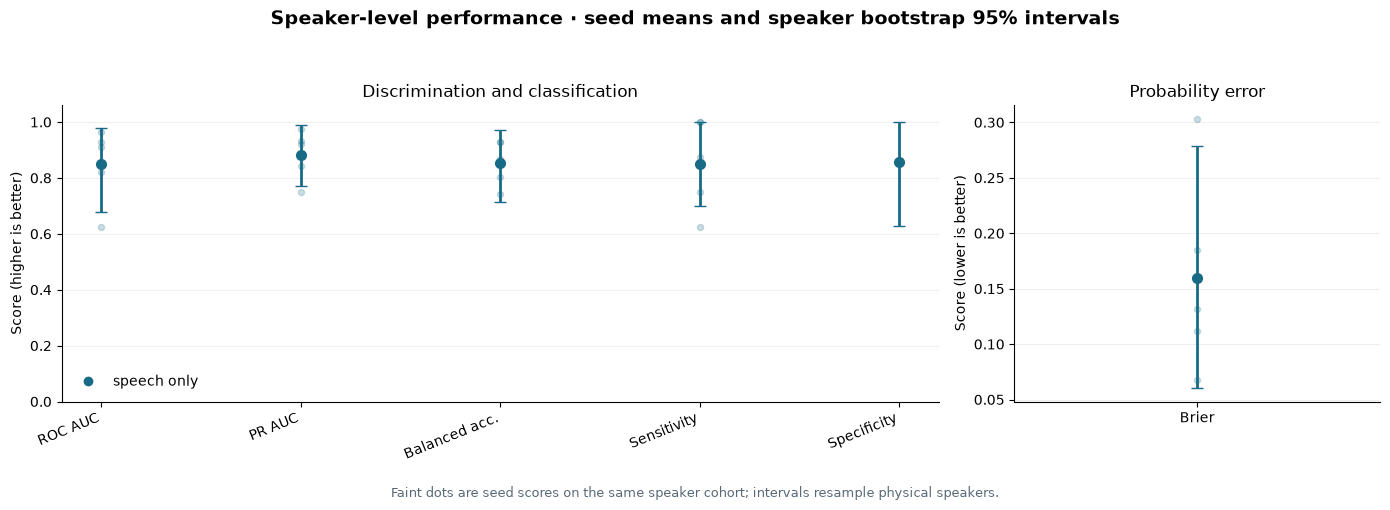

PosixPath('/Users/Noor/Documents/projects/dysarthia/v8/outputs/cache/dysarthria_detection_v8/run_2058b417224f6290/figures/v8_model_metrics.png')

In [89]:
for model_arm in result["model_arms"]:
    plot_v8_seed_curves(predictions, run_dir, model_arm)
    plot_v8_confusion(predictions, run_dir, model_arm)
    plot_v8_speaker_heatmap(predictions, run_dir, model_arm)
    plot_v8_calibration(predictions, run_dir, model_arm)
plot_v8_model_metrics(metrics, cluster_ci, run_dir)


## 8. Training and split diagnostics

The loss curves below are recorded from each inner fit and saved per epoch in `training_history.csv`. If a fold was completed by an earlier V8 runner without history, its missing epochs are marked unavailable rather than reconstructed. Fold audits retain exact speaker memberships, selected epochs, and inner-selected thresholds.

In [90]:
audit_rows = []
for path in sorted(run_dir.glob("folds/*/seed*_outer*/fold_audit.json")):
    audit = json.loads(path.read_text())
    train_ids = set(audit["train_physical_speakers"])
    test_ids = set(audit["test_physical_speakers"])
    assert train_ids.isdisjoint(test_ids)
    for inner in audit["inner_folds"]:
        inner_train = set(inner["train_physical_speakers"])
        inner_val = set(inner["validation_physical_speakers"])
        assert inner_train.isdisjoint(inner_val)
        assert inner_train.isdisjoint(test_ids) and inner_val.isdisjoint(test_ids)
        audit_rows.append({"model_arm": audit["model_arm"], "seed": audit["seed"],
                           "outer_fold": audit["outer_fold"], "inner_fold": inner["inner_fold"],
                           "best_epoch": inner["best_epoch"],
                           "n_inner_train": len(inner_train), "n_inner_validation": len(inner_val),
                           "n_outer_test": len(test_ids),
                           "selected_threshold": audit["selected_threshold"]})
audit_df = pd.DataFrame(audit_rows)
display(audit_df.head(15))
print(f"Audited {len(audit_df)} inner fits; all split-overlap assertions passed.")

history_parts = []
for path in sorted(run_dir.glob("folds/*/seed*_outer*/inner*/training_history.csv")):
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    outer_match = re.fullmatch(r"seed(\d+)_outer(\d+)", path.parents[1].name)
    inner_match = re.fullmatch(r"inner(\d+)", path.parent.name)
    if not outer_match or not inner_match:
        raise ValueError(f"Unexpected history path: {path}")
    frame["model_arm"] = path.parents[2].name
    frame["seed"] = int(outer_match.group(1))
    frame["outer_fold"] = int(outer_match.group(2))
    frame["inner_fold"] = int(inner_match.group(1))
    history_parts.append(frame)
history_df = pd.concat(history_parts, ignore_index=True) if history_parts else pd.DataFrame()
if not history_df.empty:
    print("Recorded inner-fit epoch rows:", len(history_df))
    display(history_df.groupby(["model_arm", "history_status"]).size().rename("epoch_rows").to_frame())


,model_arm,seed,outer_fold,inner_fold,best_epoch,n_inner_train,n_inner_validation,n_outer_test,selected_threshold
0,speech_only,42,0,0,5,8,4,3,0.402861
1,speech_only,42,0,1,38,8,4,3,0.402861
2,speech_only,42,0,2,6,8,4,3,0.402861
3,speech_only,42,1,0,6,8,4,3,0.422913
4,speech_only,42,1,1,35,8,4,3,0.422913
5,speech_only,42,1,2,21,8,4,3,0.422913
6,speech_only,42,2,0,6,8,4,3,0.389102
7,speech_only,42,2,1,9,8,4,3,0.389102
8,speech_only,42,2,2,3,8,4,3,0.389102
9,speech_only,42,3,0,3,8,4,3,0.384055


Audited 75 inner fits; all split-overlap assertions passed.
Recorded inner-fit epoch rows: 1983


,,epoch_rows
model_arm,history_status,
speech_only,logged,1983


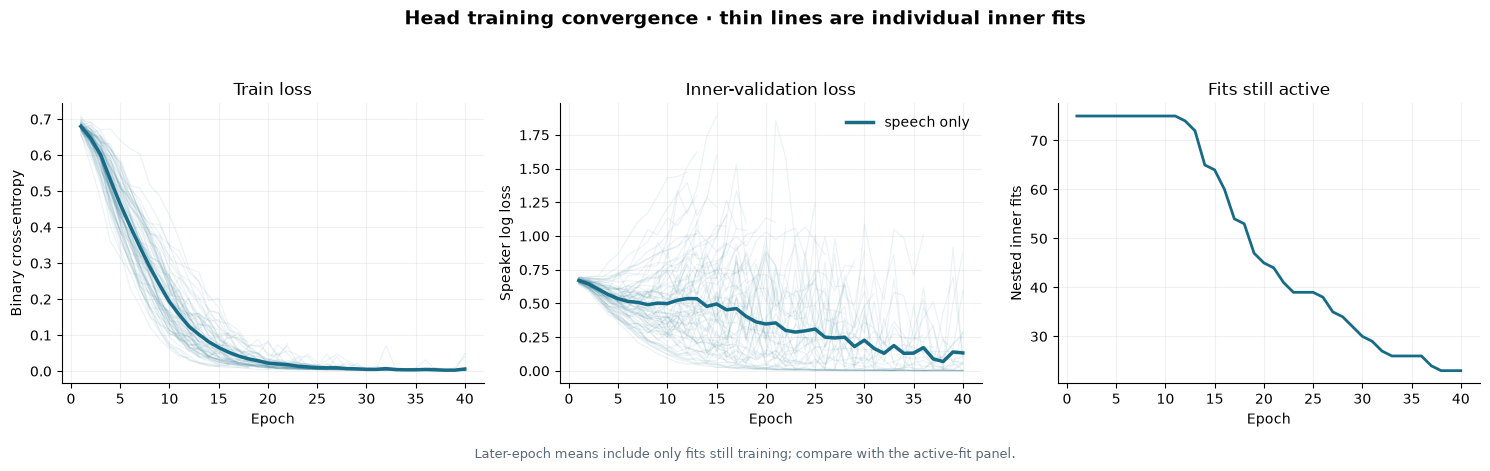

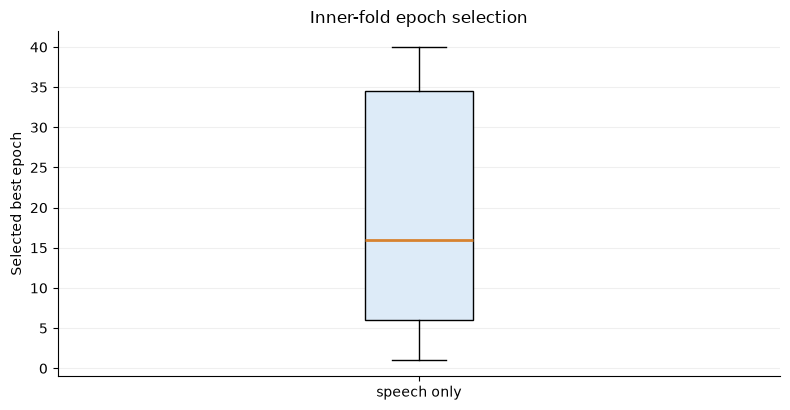

PosixPath('/Users/Noor/Documents/projects/dysarthia/v8/outputs/cache/dysarthria_detection_v8/run_2058b417224f6290/figures/v8_epoch_selection.png')

In [91]:
if not history_df.empty and history_df["validation_logloss"].notna().any():
    plot_v8_training_convergence(history_df, run_dir)
else:
    print("Recorded epoch losses unavailable; showing selected-epoch distribution.")
plot_v8_epoch_selection(audit_df, run_dir)


## 9. Reproducibility and interpretation

`run_manifest.json` records the TORGO source, configuration, pretrained weight hash, software-dependent feature specification, and run signature. `raw_inventory.csv`, `excluded_audio.csv`, `fold_audit.json`, per-fold predictions, per-epoch history, pooled speaker predictions, metrics, confidence intervals, and chart PNGs stay under this V8 output directory.

The completed internal experiment assesses the same 15 TORGO physical speakers under repeated speaker-held-out validation. The next section adds a separate zero-shot UASpeech evaluation using newly trained, locked all-TORGO deployment heads. Its result is not known until that section executes. The official pretrained bundles are documented in [Torchaudio pipelines](https://docs.pytorch.org/audio/stable/pipelines.html) and the [feature extraction API](https://docs.pytorch.org/audio/stable/generated/torchaudio.models.Wav2Vec2Model.html).

In [92]:
manifest = json.loads((run_dir / "run_manifest.json").read_text())
provenance = pd.DataFrame([{
    "run_signature": manifest["run_signature"],
    "encoder": manifest["config"]["encoder_name"],
    "pretrained_weight_sha256": manifest["pretrained_weight_sha256"],
    "raw_source_signature": manifest["raw_source_signature"],
    "physical_speakers": result["n_physical_speakers"],
    "usable_wavs": result["n_usable_utterances"],
    "previous_version_cache_used": manifest["previous_version_cache_used"],
}])
display(provenance)
print(f"Figures: {run_dir / 'figures'}")


,run_signature,encoder,pretrained_weight_sha256,raw_source_signature,physical_speakers,usable_wavs,previous_version_cache_used
0,2058b417224f62906b365541814f27dec7df7b5f3efa7a...,WAVLM_BASE,ee69baa3f5f2dd37493516acd5a5018797dd9fa25fedaf...,a7a09daace943f83a1b7805262f2cad73c9b409760171f...,15,17630,False


Figures: /Users/Noor/Documents/projects/dysarthia/v8/outputs/cache/dysarthria_detection_v8/run_2058b417224f6290/figures


## 10. UASpeech zero-shot external validation

The **M3 microphone is the prespecified primary channel**, matching V7's official protocol. The default run uses the normalized UASpeech control and dysarthric releases directly, not V6/V7 metadata or features. Set `UASPEECH_DATASET_PATH` to the directory containing `UASpeech_normalized_C` and `UASpeech_normalized_FM` if the default project `UASpeech/` path is unavailable. Set `DYSARTHRIA_V8_UASPEECH_CHANNELS=M2,M3,M4,M5,M6,M7,M8` to add secondary channel analyses; M3 must remain included.

Before opening UASpeech, the code fits and hashes **all-TORGO deployment heads** for each configured seed and model arm. Five grouped TORGO validation folds select each head's epoch count and sensitivity-constrained threshold. All 15 TORGO speakers then train the final head. The lock is reused unchanged on subsequent runs, and UASpeech labels support source-label checks and final metrics; they never fit a model, choose a threshold, calibrate probabilities, or select an arm. The external section has a separate resumable V8 cache and writes a zero-shot audit. Its speaker scores use all available utterances per UASpeech speaker, so they do not measure single-recording performance. Running this section can take substantial time because it extracts frozen WavLM features from raw UASpeech WAVs.

In [93]:
# UASpeech is an external, locked evaluation corpus. No UASpeech label enters fitting.
UASPEECH_PRIMARY_CHANNEL = "M3"
UASPEECH_CHANNELS = tuple(f"M{i}" for i in range(2, 9))
UASPEECH_ROSTER = {
    0: {"CF02", "CF03", "CF04", "CF05", "CM01", "CM04", "CM05", "CM06",
        "CM08", "CM09", "CM10", "CM12", "CM13"},
    1: {"F02", "F03", "F04", "F05", "M01", "M04", "M05", "M07",
        "M08", "M09", "M10", "M11", "M12", "M14", "M16"},
}
_UASPEECH_NAME = re.compile(
    r"(?P<speaker>(?:CF|CM|F|M)\d{2})_(?P<block>B[123])_(?P<word>.+)_(?P<channel>M[2-8])\.wav$"
)


def resolve_uaspeech_root() -> Path:
    root = Path(os.environ.get("UASPEECH_DATASET_PATH") or ROOT / "UASpeech").expanduser().resolve()
    for release in ("UASpeech_normalized_C", "UASpeech_normalized_FM"):
        if not (root / release / "audio" / "normalized").is_dir():
            raise FileNotFoundError(f"Missing normalized UASpeech release: {root / release}")
    return root


def inventory_uaspeech(root: Path, channel: str = UASPEECH_PRIMARY_CHANNEL,
                        *, expected_full: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Inventory raw normalized UASpeech without reading V6/V7 metadata or features."""
    if channel not in UASPEECH_CHANNELS:
        raise ValueError(f"UASpeech channel must be one of {UASPEECH_CHANNELS}")
    rows: list[dict[str, Any]] = []
    issues: list[dict[str, str]] = []
    for release, label in (("UASpeech_normalized_C", 0), ("UASpeech_normalized_FM", 1)):
        audio_root = root / release / "audio" / "normalized"
        if not audio_root.is_dir():
            raise FileNotFoundError(audio_root)
        paths = sorted(audio_root.glob(f"*/*_{channel}.wav"))
        if not paths:
            raise FileNotFoundError(f"No {channel} WAVs in {audio_root}")
        for path in paths:
            match = _UASPEECH_NAME.fullmatch(path.name)
            speaker = match.group("speaker") if match else None
            if (match is None or match.group("channel") != channel
                    or path.parent.name != speaker or speaker not in UASPEECH_ROSTER[label]):
                issues.append(dict(file_path=str(path), reason="speaker_label_path_disagreement"))
                continue
            try:
                info = sf.info(path)
                if info.frames <= 0 or info.samplerate <= 0:
                    raise ValueError("empty or invalid WAV")
                with sf.SoundFile(path) as wav:
                    wav.read(frames=min(1024, info.frames), dtype="float32")
            except Exception as exc:
                issues.append(dict(file_path=str(path), reason=f"audio_decode_failed: {exc}"))
                continue
            stat = path.stat()
            rel = path.relative_to(root).as_posix()
            rows.append(dict(
                file_path=str(path), relative_path=rel,
                source_id=_canonical_hash((rel, stat.st_size, stat.st_mtime_ns)),
                physical_speaker_id=speaker, label=label,
                gender="female" if speaker.startswith(("F", "CF")) else "male",
                mic_type="external", microphone=channel,
                block=match.group("block"), word_code=match.group("word"),
                release_variant=release, source_size=stat.st_size,
                source_mtime_ns=stat.st_mtime_ns,
                source_sample_rate=int(info.samplerate), source_frames=int(info.frames),
                source_seconds=float(info.duration)))
    if not rows:
        raise RuntimeError(f"No usable UASpeech {channel} audio")
    meta = pd.DataFrame(rows).sort_values("relative_path").reset_index(drop=True)
    issue_df = pd.DataFrame(issues, columns=["file_path", "reason"])
    if meta.relative_path.duplicated().any():
        raise AssertionError("Duplicate UASpeech source path")
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("Conflicting UASpeech labels for a physical speaker")
    if expected_full:
        for label, expected in UASPEECH_ROSTER.items():
            observed = set(meta.loc[meta.label.eq(label), "physical_speaker_id"])
            if observed != expected:
                raise AssertionError(
                    f"UASpeech {channel} speaker roster mismatch at label {label}: "
                    f"missing={sorted(expected-observed)}, extra={sorted(observed-expected)}")
        # The prespecified V7 M3 protocol contains 21,126 decodable WAVs.
        if channel == UASPEECH_PRIMARY_CHANNEL and len(meta) != 21_126:
            raise AssertionError(f"UASpeech M3 expected 21,126 valid WAVs, found {len(meta)}")
    return meta, issue_df


def _verified_torgo_run_for_deployment(config: Config, run_dir: Path):
    """Load only the completed V8 TORGO feature set before any external access."""
    run_manifest = json.loads((run_dir / "run_manifest.json").read_text())
    feature_manifest = json.loads((run_dir / "features" / "manifest.json").read_text())
    if run_manifest.get("pipeline_signature") != PIPELINE_SIGNATURE:
        raise RuntimeError("V8 TORGO pipeline signature mismatch")
    if _canonical_hash(run_manifest.get("config")) != _canonical_hash(asdict(config)):
        raise RuntimeError("V8 TORGO configuration differs from the requested deployment configuration")
    if not feature_manifest.get("complete") or feature_manifest.get("extraction_errors"):
        raise RuntimeError("A complete, error-free V8 TORGO feature set is required")
    if feature_manifest.get("source_signature") != run_manifest.get("raw_source_signature"):
        raise RuntimeError("TORGO raw inventory and usable feature signatures differ")
    if feature_manifest.get("feature_spec") != run_manifest.get("feature_spec"):
        raise RuntimeError("TORGO feature recipe differs from the run manifest")
    meta = pd.read_csv(run_dir / "features" / "usable_metadata.csv")
    speech = np.load(run_dir / "features" / "speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(run_dir / "features" / "acoustic_features.npy", mmap_mode="r")
    if (len(meta) != len(speech) or len(meta) != len(acoustic)
            or source_signature(meta) != run_manifest["raw_source_signature"]
            or set(meta.physical_speaker_id) != OFFICIAL_TORGO_ROSTER):
        raise RuntimeError("V8 TORGO feature rows or speaker roster are inconsistent")
    torgo_root = Path(run_manifest["dataset_root"]).resolve()
    if not all(Path(path).resolve().is_relative_to(torgo_root) for path in meta.file_path):
        raise RuntimeError("Deployment training metadata contains non-TORGO audio")
    return run_manifest, meta, speech, acoustic


def _verify_torgo_deployment_lock(lock: dict[str, Any], config: Config,
                                  run_dir: Path, run_manifest: dict[str, Any]) -> None:
    expected_arms = {"speech_only", "fusion"} if config.use_fusion else {"speech_only"}
    expected = {(arm, int(seed)) for arm in expected_arms for seed in config.seeds}
    records = lock.get("models", [])
    observed = {(record.get("model_arm"), int(record.get("seed", -1))) for record in records}
    if (lock.get("source_corpus") != "TORGO only"
            or lock.get("pipeline_signature") != PIPELINE_SIGNATURE
            or lock.get("run_signature") != run_manifest["run_signature"]
            or lock.get("torgo_source_signature") != run_manifest["raw_source_signature"]
            or lock.get("pretrained_weight_sha256") != run_manifest["pretrained_weight_sha256"]
            or observed != expected or len(records) != len(expected)):
        raise RuntimeError("TORGO deployment lock provenance or model set does not match")
    for record in records:
        for path_key, hash_key in (("checkpoint", "checkpoint_sha256"),
                                   ("acoustic_scaler", "acoustic_scaler_sha256")):
            path = (run_dir / record[path_key]).resolve()
            if not path.is_relative_to(run_dir.resolve()) or not path.is_file():
                raise RuntimeError(f"Locked deployment artifact is missing: {path}")
            if _file_sha256(path) != record[hash_key]:
                raise RuntimeError(f"Locked deployment artifact changed: {path}")


def lock_v8_torgo_deployment(config: Config, run_dir: Path) -> dict[str, Any]:
    """Fit and freeze all-TORGO heads, thresholds and scalers before UASpeech is read."""
    run_dir = Path(run_dir).resolve()
    run_manifest, meta, speech, acoustic = _verified_torgo_run_for_deployment(config, run_dir)
    lock_path = run_dir / "deployment" / "v8_torgo_model_lock.json"
    if lock_path.is_file():
        lock = json.loads(lock_path.read_text())
        _verify_torgo_deployment_lock(lock, config, run_dir, run_manifest)
        return lock
    device = choose_device()
    speakers = set(meta.physical_speaker_id)
    records = []
    for use_fusion in ([False, True] if config.use_fusion else [False]):
        arm = "fusion" if use_fusion else "speech_only"
        for seed in config.seeds:
            seed_dir = run_dir / "deployment" / arm / f"seed{seed}"
            inner_rows = []
            best_epochs = []
            for inner, train_speakers, val_speakers in grouped_speaker_splits(
                    meta, seed + 731, config.outer_folds):
                model, best_epoch, store = train_head(
                    config, meta, speech, acoustic, train_speakers, val_speakers,
                    use_fusion=use_fusion, seed=seed * 1000 + 500 + inner,
                    run_signature=run_manifest["run_signature"],
                    checkpoint_dir=seed_dir / f"inner{inner}", device=device)
                held_out = predict_speakers(model, store, val_speakers,
                                            config.max_utterances_per_bag)
                held_out["inner_fold"] = inner
                inner_rows.append(held_out)
                best_epochs.append(best_epoch)
                del model, store
            inner_oof = pd.concat(inner_rows, ignore_index=True)
            if (set(inner_oof.physical_speaker_id) != speakers
                    or inner_oof.physical_speaker_id.duplicated().any()):
                raise AssertionError("Deployment inner OOF must cover each TORGO speaker once")
            threshold = select_threshold(inner_oof)
            final_epochs = max(1, int(np.median(best_epochs).round()))
            model, _, store = train_head(
                config, meta, speech, acoustic, speakers, None,
                use_fusion=use_fusion, seed=seed * 1000 + 999,
                run_signature=run_manifest["run_signature"],
                checkpoint_dir=seed_dir / "final", device=device, epochs=final_epochs)
            del model, store
            _atomic_csv(seed_dir / "torgo_inner_oof_speakers.csv", inner_oof)
            checkpoint = seed_dir / "final" / "best.pt"
            scaler = seed_dir / "final" / "acoustic_scaler.npz"
            records.append(dict(
                model_arm=arm, seed=int(seed), threshold=float(threshold),
                threshold_source="TORGO grouped inner speaker OOF only",
                inner_folds=int(config.outer_folds),
                final_epochs=int(final_epochs),
                checkpoint=str(checkpoint.relative_to(run_dir)),
                checkpoint_sha256=_file_sha256(checkpoint),
                acoustic_scaler=str(scaler.relative_to(run_dir)),
                acoustic_scaler_sha256=_file_sha256(scaler),
                torgo_inner_oof=str((seed_dir / "torgo_inner_oof_speakers.csv").relative_to(run_dir))))
            print(f"Locked V8 TORGO {arm} seed {seed}: threshold={threshold:.4f}, "
                  f"final epochs={final_epochs}", flush=True)
    lock = dict(source_corpus="TORGO only", pipeline_signature=PIPELINE_SIGNATURE,
                run_signature=run_manifest["run_signature"],
                torgo_source_signature=run_manifest["raw_source_signature"],
                pretrained_weight_sha256=run_manifest["pretrained_weight_sha256"],
                external_dataset_used_for_training=False,
                external_dataset_used_for_threshold_selection=False,
                primary_external_channel=UASPEECH_PRIMARY_CHANNEL,
                model_selection="all configured arms and seeds are evaluated; no external selection",
                models=records)
    _atomic_json(lock_path, lock)
    return lock


def predict_uaspeech_from_lock(config: Config, run_dir: Path, lock: dict[str, Any],
                                meta: pd.DataFrame, speech: np.ndarray,
                                acoustic: np.ndarray, device: torch.device) -> pd.DataFrame:
    """Apply every locked TORGO model; external labels enter output rows only."""
    rows = []
    for record in lock["models"]:
        model = _new_head(config, speech, acoustic, record["model_arm"] == "fusion", device)
        checkpoint = run_dir / record["checkpoint"]
        if _file_sha256(checkpoint) != record["checkpoint_sha256"]:
            raise RuntimeError(f"Locked checkpoint changed before external inference: {checkpoint}")
        model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
        scaler_path = run_dir / record["acoustic_scaler"]
        if _file_sha256(scaler_path) != record["acoustic_scaler_sha256"]:
            raise RuntimeError(f"Locked acoustic scaler changed: {scaler_path}")
        with np.load(scaler_path) as saved:
            scaler = (saved["mean"].copy(), saved["scale"].copy())
        store = BagStore(meta, speech, acoustic, scaler, device)
        prediction = predict_speakers(model, store, set(meta.physical_speaker_id),
                                      config.max_utterances_per_bag)
        prediction["seed"] = record["seed"]
        prediction["model_arm"] = record["model_arm"]
        prediction["threshold"] = record["threshold"]
        prediction["predicted_label"] = (
            prediction.probability >= record["threshold"]).astype(int)
        prediction["checkpoint_sha256"] = record["checkpoint_sha256"]
        rows.append(prediction)
        del model, store
    return pd.concat(rows, ignore_index=True)


def run_v8_uaspeech_external(config: Config, run_dir: Path,
                              channels: tuple[str, ...] = (UASPEECH_PRIMARY_CHANNEL,)) -> dict[str, Any]:
    """Locked zero-shot external validation; M3 is the prespecified primary channel."""
    config.validate()
    run_dir = Path(run_dir).resolve()
    channels = tuple(dict.fromkeys(channel.strip().upper() for channel in channels))
    if not channels or any(channel not in UASPEECH_CHANNELS for channel in channels):
        raise ValueError(f"Choose one or more UASpeech channels from {UASPEECH_CHANNELS}")
    if UASPEECH_PRIMARY_CHANNEL not in channels:
        raise ValueError("The primary M3 channel must be included")
    # The lock is written and verified before even resolving the UASpeech root.
    lock = lock_v8_torgo_deployment(config, run_dir)
    root = resolve_uaspeech_root()
    run_manifest = json.loads((run_dir / "run_manifest.json").read_text())
    device = choose_device()
    encoder, weight_sha, _ = load_pretrained(
        config, CACHE_ROOT / "pretrained" / config.encoder_name, device)
    if weight_sha != lock["pretrained_weight_sha256"]:
        raise RuntimeError("External encoder weights differ from frozen TORGO encoder")
    feature_spec = dict(run_manifest["feature_spec"],
                        external_preprocessing="normalized_UASpeech_mic_unknown_trim25_no_gate_v1")
    external_dir = run_dir / "external_uaspeech"
    external_dir.mkdir(parents=True, exist_ok=True)
    all_predictions, all_metrics, all_ci = [], [], []
    inventory_signatures, channel_counts = {}, {}
    for channel in channels:
        channel_dir = external_dir / channel
        meta, inventory_issues = inventory_uaspeech(root, channel)
        inventory_signatures[channel] = source_signature(meta)
        _atomic_csv(channel_dir / "raw_inventory.csv", meta)
        usable, speech, acoustic, feature_issues = extract_dataset_features(
            meta, encoder, config, channel_dir, feature_spec, device)
        issues = pd.concat((inventory_issues, feature_issues), ignore_index=True)
        _atomic_csv(channel_dir / "excluded_audio.csv", issues)
        if set(usable.physical_speaker_id) != set.union(*UASPEECH_ROSTER.values()):
            raise RuntimeError(f"UASpeech {channel} feature extraction lost a physical speaker")
        if channel == UASPEECH_PRIMARY_CHANNEL and len(usable) != 21_126:
            raise RuntimeError("UASpeech M3 feature extraction lost valid recordings")
        prediction = predict_uaspeech_from_lock(
            config, run_dir, lock, usable, speech, acoustic, device)
        expected = set(usable.physical_speaker_id)
        for (_, _), frame in prediction.groupby(["model_arm", "seed"]):
            if len(frame) != len(expected) or set(frame.physical_speaker_id) != expected:
                raise AssertionError("External predictions omit or duplicate UASpeech speakers")
        prediction["channel"] = channel
        metrics = _seed_metric_table(prediction)
        metrics["channel"] = channel
        cluster_ci = speaker_cluster_bootstrap_ci(prediction)
        cluster_ci["channel"] = channel
        _atomic_csv(channel_dir / "v8_uaspeech_speaker_predictions.csv", prediction)
        _atomic_csv(channel_dir / "v8_uaspeech_per_seed_metrics.csv", metrics)
        _atomic_csv(channel_dir / "v8_uaspeech_speaker_cluster_ci.csv", cluster_ci)
        all_predictions.append(prediction)
        all_metrics.append(metrics)
        all_ci.append(cluster_ci)
        channel_counts[channel] = dict(n_valid_inventory=len(meta),
                                       n_usable=len(usable), n_excluded=len(issues),
                                       n_physical_speakers=len(expected))
        print(f"V8 UASpeech {channel}: {len(usable)} WAVs, "
              f"{len(expected)} speakers, {len(issues)} excluded", flush=True)
    del encoder
    predictions = pd.concat(all_predictions, ignore_index=True)
    metrics = pd.concat(all_metrics, ignore_index=True)
    ci = pd.concat(all_ci, ignore_index=True)
    _atomic_csv(external_dir / "v8_uaspeech_speaker_predictions.csv", predictions)
    _atomic_csv(external_dir / "v8_uaspeech_per_seed_metrics.csv", metrics)
    _atomic_csv(external_dir / "v8_uaspeech_speaker_cluster_ci.csv", ci)
    summary = dict(complete=True, evaluation="zero_shot_external",
                   primary_channel=UASPEECH_PRIMARY_CHANNEL, channels=list(channels),
                   source_corpus_for_training="TORGO only",
                   external_dataset="UASpeech normalized C and FM",
                   external_dataset_used_for_training=False,
                   external_dataset_used_for_fine_tuning=False,
                   external_dataset_used_for_threshold_selection=False,
                   external_dataset_used_for_calibration=False,
                   external_dataset_used_for_model_selection=False,
                   evaluation_unit="physical_speaker", n_seeds=len(config.seeds),
                   model_arms=sorted({record["model_arm"] for record in lock["models"]}),
                   channel_counts=channel_counts,
                   per_channel={channel: _metric_summary(metrics[metrics.channel.eq(channel)])
                                for channel in channels})
    _atomic_json(external_dir / "v8_uaspeech_summary.json", summary)
    _atomic_json(external_dir / "v8_uaspeech_zero_shot_audit.json", dict(
        torgo_model_lock_sha256=_file_sha256(run_dir / "deployment" / "v8_torgo_model_lock.json"),
        torgo_run_signature=run_manifest["run_signature"],
        torgo_source_signature=run_manifest["raw_source_signature"],
        pretrained_weight_sha256=weight_sha,
        uaspeech_root=str(root), uaspeech_inventory_signatures=inventory_signatures,
        channels=list(channels), primary_channel=UASPEECH_PRIMARY_CHANNEL,
        source_releases=["UASpeech_normalized_C", "UASpeech_normalized_FM"],
        external_dataset_used_for_training=False,
        external_dataset_used_for_fine_tuning=False,
        external_dataset_used_for_threshold_selection=False,
        external_dataset_used_for_calibration=False,
        external_dataset_used_for_model_selection=False,
        frozen_checkpoint_sha256={f"{r['model_arm']}_seed{r['seed']}": r["checkpoint_sha256"]
                                  for r in lock["models"]}))
    _atomic_json(OUT / "v8_latest_external_run.json", dict(
        output_dir=str(external_dir),
        summary_file=str(external_dir / "v8_uaspeech_summary.json"),
        torgo_run_signature=run_manifest["run_signature"]))
    return summary


In [94]:
external_channels = tuple(
    item.strip().upper() for item in
    os.environ.get("DYSARTHRIA_V8_UASPEECH_CHANNELS", "M3").split(",") if item.strip()
)
external_summary = run_v8_uaspeech_external(config, run_dir, external_channels)
external_dir = run_dir / "external_uaspeech"
external_metrics = pd.read_csv(external_dir / "v8_uaspeech_per_seed_metrics.csv")
external_ci = pd.read_csv(external_dir / "v8_uaspeech_speaker_cluster_ci.csv")
print(f"Locked V8 UASpeech results: {external_dir}")
display(external_metrics.loc[external_metrics.channel.eq(UASPEECH_PRIMARY_CHANNEL)])
display(external_ci.loc[external_ci.channel.eq(UASPEECH_PRIMARY_CHANNEL)])

V8 UASpeech M3: 21126 WAVs, 28 speakers, 39 excluded
Locked V8 UASpeech results: /Users/Noor/Documents/projects/dysarthia/v8/outputs/cache/dysarthria_detection_v8/run_2058b417224f6290/external_uaspeech


,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE,channel
0,speech_only,42,28,0.821429,0.833333,0.666667,1.0,0.800000,0.948718,0.966138,0.151607,0.167304,M3
1,speech_only,43,28,0.892857,0.900000,0.800000,1.0,0.888889,0.964103,0.975000,0.107202,0.137316,M3
2,speech_only,44,28,0.857143,0.866667,0.733333,1.0,0.846154,0.964103,0.974200,0.126611,0.147763,M3
3,speech_only,45,28,0.821429,0.833333,0.666667,1.0,0.800000,0.984615,0.987712,0.149484,0.199290,M3
4,speech_only,46,28,0.857143,0.866667,0.733333,1.0,0.846154,0.969231,0.978889,0.117500,0.163363,M3


,model_arm,metric,lower_95,upper_95,n_resamples,resampling_unit,stratified_by_diagnosis,same_speaker_draw_across_seeds,channel
0,speech_only,ROC_AUC,0.897436,1.000000,1000,physical_speaker,True,True,M3
1,speech_only,PR_AUC,0.935459,1.000000,1000,physical_speaker,True,True,M3
2,speech_only,Balanced_Accuracy,0.753333,0.953333,1000,physical_speaker,True,True,M3
3,speech_only,Sensitivity,0.506667,0.906667,1000,physical_speaker,True,True,M3
4,speech_only,Specificity,1.000000,1.000000,1000,physical_speaker,True,True,M3
5,speech_only,Brier,0.048301,0.224068,1000,physical_speaker,True,True,M3


### Primary UASpeech M3 figures

These show the 28 external physical speakers across the same five frozen TORGO-trained seeds. The plots are descriptive; the CSV predictions, per-seed metrics, speaker-bootstrap intervals, TORGO lock, and zero-shot audit above are the numerical sources.

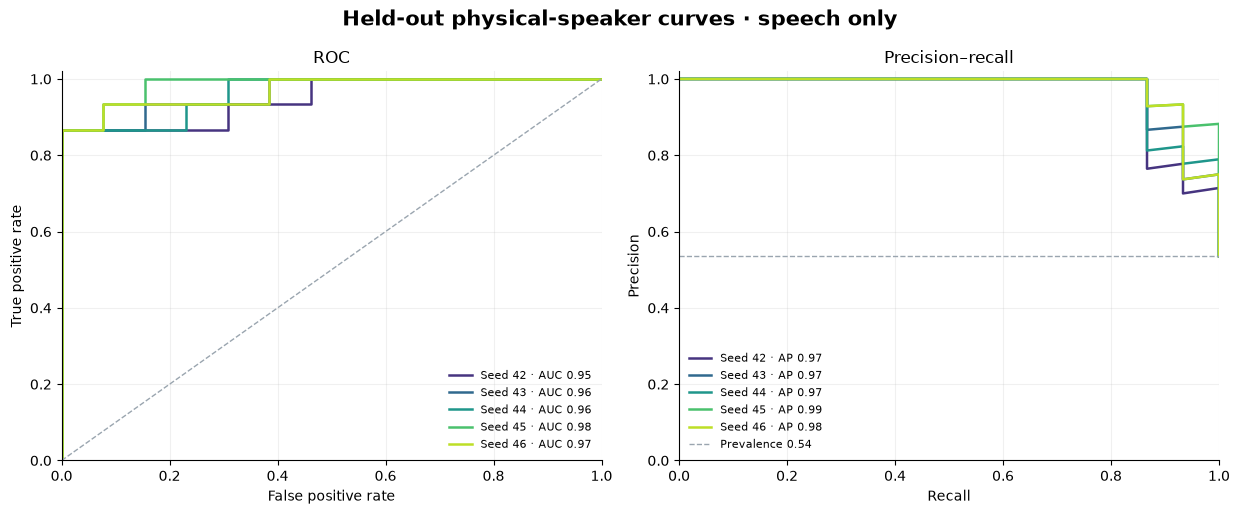

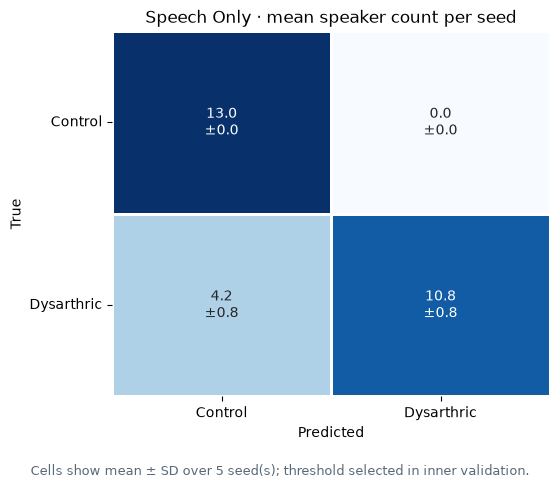

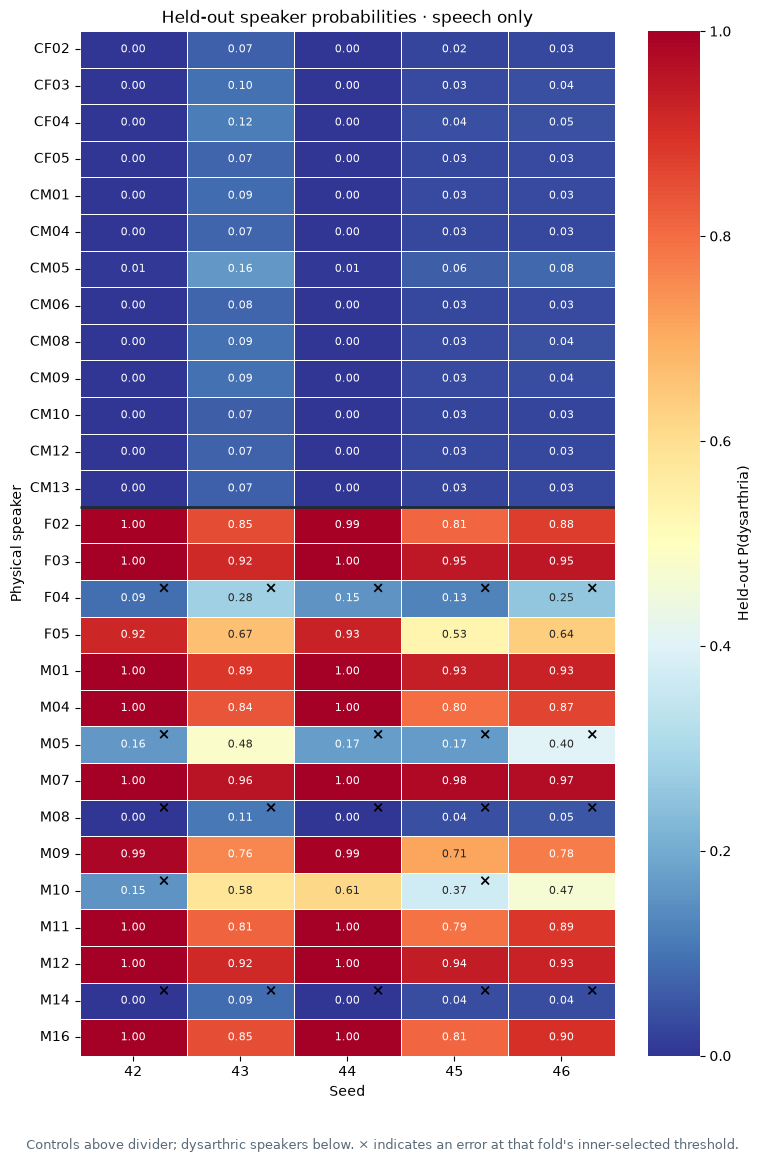

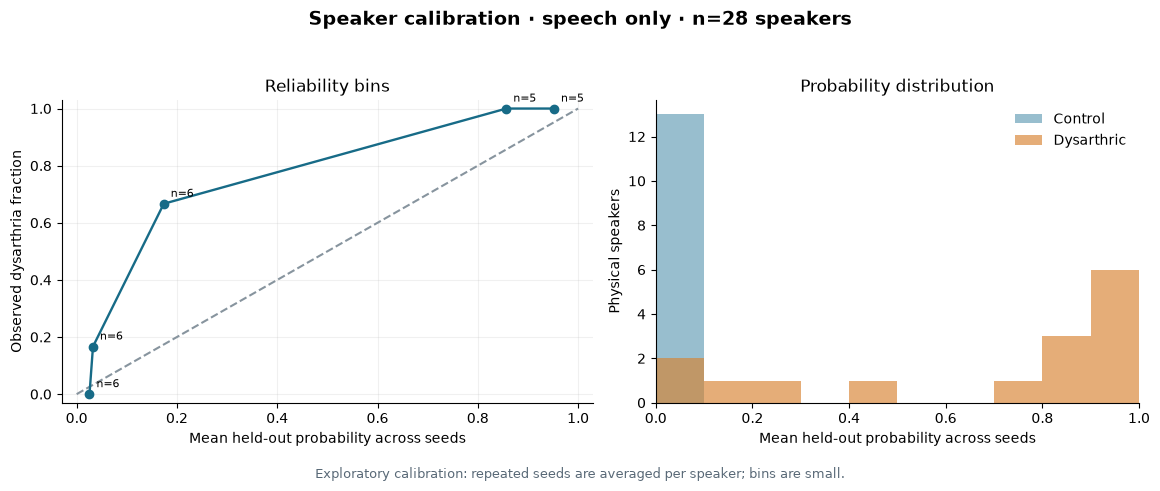

In [95]:
external_predictions = pd.read_csv(
    external_dir / "M3" / "v8_uaspeech_speaker_predictions.csv"
)
for model_arm in external_summary["model_arms"]:
    plot_v8_seed_curves(external_predictions, external_dir / "M3", model_arm)
    plot_v8_confusion(external_predictions, external_dir / "M3", model_arm)
    plot_v8_speaker_heatmap(external_predictions, external_dir / "M3", model_arm)
    plot_v8_calibration(external_predictions, external_dir / "M3", model_arm)

## 11. V8 publication completion around the frozen reference

The existing WavLM Last-4 trainable layer mix with speaker attention and mean context is the primary V8 reference. Its successful TORGO and official UASpeech M3 run was copied and SHA256-verified at `v8_publication_completion/frozen_reference/` before any additional experiment. The reference checkpoints, thresholds, predictions, and original notebook are preserved there.

The publication modules use the same five TORGO seeds and physical-speaker splits for the controlled 2 × 2 component ablation. All new external analyses use the frozen TORGO models and thresholds. UASpeech M3 remains the prespecified primary channel; M2–M8 are descriptive robustness checks. UASpeech was studied in earlier project versions, so these results are locked zero-shot cross-corpus evaluations, not historically untouched prospective validation.

Run the next cell to resume any publication experiment and regenerate six tables, nine figures, traceability checks, and the final audit. Channel feature extraction may take substantial time and resumes from keyed per-recording shards. Results and figures are generated from saved predictions; missing work is reported as incomplete. High performance from duration/background controls must be treated as a possible confound, not hidden.


In [96]:
# Resume publication-completion work from the separately frozen V8 run.
# This cell does not modify the previously completed TORGO or M3 run artifacts.
import sys
from pathlib import Path
_v8_here = Path.cwd().resolve()
_v8_project = _v8_here if (_v8_here / "v8" / "dysarthria_v8.ipynb").exists() else _v8_here.parent
if str(_v8_project) not in sys.path:
    sys.path.insert(0, str(_v8_project))
from v8.publication.workflow import run_publication_completion
publication_results = run_publication_completion(
    stages=("primary", "ablations", "budgets", "baselines", "matched_content", "silence", "channels", "report")
)


RuntimeError: Original reference modified: /Users/Noor/Documents/projects/dysarthia/v8/outputs/cache/dysarthria_detection_v8/run_2058b417224f6290/external_uaspeech/M3/figures/v8_speech_only_calibration.png

### Publication result and audit

All table entries are calculated from saved speaker predictions and per-seed metric CSVs. The final audit checks split membership, checkpoint hashes, source signatures, result hashes, and figure inputs before declaring completion. An incomplete stage remains visibly incomplete.


In [ ]:
from IPython.display import display
import pandas as pd
_publication_root = _v8_project / "v8" / "v8_publication_completion"
for _number, _name in enumerate(("table01_torgo_primary", "table02_component_ablation", "table03_uaspeech_m3", "table04_channel_robustness", "table05_utterance_budget", "table06_sanity_controls"), start=1):
    _table = _publication_root / "publication" / "tables" / f"v8_pub_{_name}.csv"
    if _table.exists():
        print(f"Table {_number}: {_name}")
        display(pd.read_csv(_table))
_audit = _publication_root / "publication" / "publication_audit.txt"
if _audit.exists():
    print(_audit.read_text())
else:
    print("V8 PUBLICATION COMPLETION AUDIT NOT YET GENERATED")


Table 1: table01_torgo_primary


,model_arm,corpus,n_seeds,n_speakers_min,n_speakers_max,status,Accuracy_mean,Accuracy_sd,Accuracy,Balanced_Accuracy_mean,...,PR_AUC_sd,PR_AUC,Brier_mean,Brier_sd,Brier,ECE_mean,ECE_sd,ECE,model,n_recordings
0,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,5,15,15,COMPLETE,0.853333,0.086923,0.853 ± 0.087,0.853571,...,0.08932,0.884 ± 0.089,0.159843,0.090498,0.160 ± 0.090,0.230001,0.115914,0.230 ± 0.116,WavLM Last-4 Mix + Attention (V8 Reference),17630.0


Table 2: table02_component_ablation


,model_arm,n_seeds,n_speakers_min,n_speakers_max,status,Accuracy_mean,Accuracy_sd,Accuracy,Balanced_Accuracy_mean,Balanced_Accuracy_sd,...,PR_AUC_mean,PR_AUC_sd,PR_AUC,Brier_mean,Brier_sd,Brier,ECE_mean,ECE_sd,ECE,model
0,A1,5,15,15,COMPLETE,0.826667,0.101105,0.827 ± 0.101,0.828571,0.100699,...,0.914471,0.055336,0.914 ± 0.055,0.157736,0.093161,0.158 ± 0.093,0.216535,0.073832,0.217 ± 0.074,WavLM Last Layer + Mean Pooling
1,A2,5,15,15,COMPLETE,0.826667,0.059628,0.827 ± 0.060,0.825000,0.055616,...,0.855114,0.080764,0.855 ± 0.081,0.181296,0.074508,0.181 ± 0.075,0.281867,0.068058,0.282 ± 0.068,WavLM Last Layer + Attention
2,B1,5,15,15,COMPLETE,0.826667,0.101105,0.827 ± 0.101,0.826786,0.101330,...,0.936689,0.028056,0.937 ± 0.028,0.140102,0.088118,0.140 ± 0.088,0.197147,0.085951,0.197 ± 0.086,WavLM Last-4 Mix + Mean Pooling
3,B2,5,15,15,COMPLETE,0.853333,0.086923,0.853 ± 0.087,0.853571,0.081490,...,0.883598,0.089320,0.884 ± 0.089,0.159843,0.090498,0.160 ± 0.090,0.230001,0.115914,0.230 ± 0.116,WavLM Last-4 Mix + Attention (V8 Reference)


Table 3: table03_uaspeech_m3


...

Table 5: table05_utterance_budget


,model_arm,corpus,channel,budget,n_seeds,n_speakers_min,n_speakers_max,status,Accuracy_mean,Accuracy_sd,...,Balanced_Accuracy_sampling_sd,Sensitivity_sampling_sd,Specificity_sampling_sd,F1_dysarthric_sampling_sd,ROC_AUC_sampling_sd,PR_AUC_sampling_sd,Brier_sampling_sd,ECE_sampling_sd,model,n_recordings
0,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,TORGO,1,5,15,15,COMPLETE,0.654533,0.033975,...,0.095609,0.099660,0.172557,0.068494,0.101147,0.078945,0.067809,0.070519,WavLM Last-4 Mix + Attention (V8 Reference),15.0
1,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,TORGO,10,5,15,15,COMPLETE,0.796667,0.070774,...,0.075184,0.084788,0.125988,0.064311,0.066984,0.053445,0.044459,0.049817,WavLM Last-4 Mix + Attention (V8 Reference),150.0
2,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,TORGO,20,5,15,15,COMPLETE,0.813067,0.080216,...,0.066490,0.073219,0.109055,0.057011,0.051448,0.041659,0.033767,0.044975,WavLM Last-4 Mix + Attention (V8 Reference),300.0
3,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,TORGO,5,5,15,15,COMPLETE,0.763867,0.058299,...,0.087577,0.095110,0.150811,0.071479,0.080791,0.064090,0.053415,0.055435,WavLM Last-4 Mix + Attention (V8 Reference),75.0
4,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,TORGO,50,5,15,15,COMPLETE,0.829467,0.080049,...,0.052333,0.050444,0.086442,0.043822,0.039444,0.031604,0.023841,0.036959,WavLM Last-4 Mix + Attention (V8 Reference),750.0
5,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,TORGO,all,5,15,15,COMPLETE,0.853333,0.086923,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,WavLM Last-4 Mix + Attention (V8 Reference),17630.0
6,WavLM Last-4 Mix + Attention (V8 Reference),UASpeech,M3,1,5,28,28,COMPLETE,0.818429,0.014376,...,0.062612,0.098767,0.072618,0.072726,0.056322,0.039971,0.050450,0.051485,WavLM Last-4 Mix + Attention (V8 Reference),28.0
7,WavLM Last-4 Mix + Attention (V8 Reference),UASpeech,M3,10,5,28,28,COMPLETE,0.843286,0.025171,...,0.038202,0.075747,0.012114,0.052942,0.026485,0.014473,0.027841,0.030922,WavLM Last-4 Mix + Attention (V8 Reference),280.0
8,WavLM Last-4 Mix + Attention (V8 Reference),UASpeech,M3,20,5,28,28,COMPLETE,0.848714,0.027153,...,0.031560,0.062761,0.005211,0.043388,0.020010,0.010747,0.020897,0.023455,WavLM Last-4 Mix + Attention (V8 Reference),560.0
9,WavLM Last-4 Mix + Attention (V8 Reference),UASpeech,M3,5,5,28,28,COMPLETE,0.835214,0.024847,...,0.043413,0.082864,0.025686,0.059504,0.031916,0.018509,0.032703,0.036240,WavLM Last-4 Mix + Attention (V8 Reference),140.0


Table 6: table06_sanity_controls


,model_arm,corpus,n_seeds,n_speakers_min,n_speakers_max,status,Accuracy_mean,Accuracy_sd,Accuracy,Balanced_Accuracy_mean,...,Brier_sd,Brier,ECE_mean,ECE_sd,ECE,model,n_recordings,analysis,channel,n_matched_prompts
0,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,5,15,15,COMPLETE,0.853333,0.086923,0.853 ± 0.087,0.853571,...,0.090498,0.160 ± 0.090,0.230001,0.115914,0.230 ± 0.116,WavLM Last-4 Mix + Attention (V8 Reference),17630.0,primary_reference,NaN,NaN
1,WavLM Last-4 Mix + Attention (V8 Reference),UASpeech,5,28,28,COMPLETE,0.850000,0.029881,0.850 ± 0.030,0.860000,...,0.019575,0.130 ± 0.020,0.163007,0.023598,0.163 ± 0.024,WavLM Last-4 Mix + Attention (V8 Reference),21126.0,primary_reference,M3,NaN
2,WavLM Last-4 Mix + Attention (V8 Reference),TORGO,5,15,15,COMPLETE,0.480000,0.055777,0.480 ± 0.056,0.451786,...,0.024092,0.391 ± 0.024,0.397247,0.007259,0.397 ± 0.007,WavLM Last-4 Mix + Attention (V8 Reference),750.0,silence,original_TORGO,NaN
3,WavLM Last-4 Mix + Attention (V8 Reference),UASpeech,5,28,28,COMPLETE,0.571429,0.061859,0.571 ± 0.062,0.538462,...,0.082791,0.313 ± 0.083,0.360538,0.070317,0.361 ± 0.070,WavLM Last-4 Mix + Attention (V8 Reference),1259.0,silence,M3,NaN
4,Duration-only logistic regression,TORGO,5,15,15,COMPLETE,0.706667,0.076012,0.707 ± 0.076,0.689286,...,0.009894,0.109 ± 0.010,0.201345,0.051439,0.201 ± 0.051,Duration-only logistic regression,17630.0,duration,NaN,NaN
5,Duration-only logistic regression,UASpeech,5,28,28,COMPLETE,0.642857,0.000000,0.643 ± 0.000,0.666667,...,0.000000,0.275 ± 0.000,0.337297,0.000000,0.337 ± 0.000,Duration-only logistic regression,21126.0,duration,NaN,NaN
6,Artifact-only logistic regression,TORGO,5,15,15,COMPLETE,0.600000,0.000000,0.600 ± 0.000,0.575000,...,0.009108,0.123 ± 0.009,0.184674,0.052698,0.185 ± 0.053,Artifact-only logistic regression,17630.0,artifact,NaN,NaN
7,Artifact-only logistic regression,UASpeech,5,28,28,COMPLETE,0.778571,0.088928,0.779 ± 0.089,0.793333,...,0.000000,0.311 ± 0.000,0.380775,0.000000,0.381 ± 0.000,Artifact-only logistic regression,21126.0,artifact,NaN,NaN
8,WavLM Last-4 Mix + Attention (V8 Reference),UASpeech,5,25,25,COMPLETE,0.856000,0.045607,0.856 ± 0.046,0.871429,...,0.020357,0.127 ± 0.020,0.177237,0.034789,0.177 ± 0.035,WavLM Last-4 Mix + Attention (V8 Reference),7650.0,matched_content,M3,306.0


V8 PUBLICATION COMPLETION AUDIT

Reference V8 frozen:
PASS

Physical-speaker leakage checks:
PASS

Five TORGO seeds complete:
YES

Nested inner speaker validation:
PASS

V8 component ablation complete:
YES

Layer-mix contribution evaluated:
YES

Attention-pooling contribution evaluated:
YES

Speaker-bootstrap uncertainty complete:
YES

Utterance-budget analysis complete:
YES

Silence/background sanity check:
YES

Duration-only sanity baseline:
YES

Artifact-only baseline:
YES

Matched-content UASpeech analysis:
YES

UASpeech M3 locked zero-shot complete:
YES

UASpeech M2-M8 diagnostic complete:
YES

UASpeech used for training:
NO

UASpeech used for fine-tuning:
NO

UASpeech used for threshold selection:
NO

UASpeech used for calibration:
NO

UASpeech used for model selection:
NO

Publication tables generated:
YES

Publication figures generated:
YES

Traceability audit:
PASS

TABLE AND FIGURE TRACEABILITY
PRIMARY TORGO TABLE: PASS
ABLATION TABLE: PASS
UASPEECH M3 TABLE: PASS
CHANNEL TAB

## 12. Additional paper figures from frozen V8 results

The following cell generates four focused publication figures from the saved frozen-reference predictions and training records. It makes no new model-selection decision and does not retrain V8. The duration and matched-word figures are descriptive diagnostics; neither establishes disease-specific signal after confound matching. PNG, vector PDF, plotted CSV data, and source hashes are saved under `v8_research_completion/figures/`.


In [ ]:
from IPython.display import Image, display
from v8.v8_research_completion.make_paper_figures import main as make_v8_paper_figures

make_v8_paper_figures()
_extra_figure_dir = _v8_project / "v8" / "v8_research_completion" / "figures"
for _figure_stem in (
    "fig10_duration_vs_v8_score",
    "fig11_matched_words_paired_scores",
    "fig12_paired_ablation_deltas",
    "fig13_epoch_selection",
):
    _pdf = _extra_figure_dir / f"{_figure_stem}.pdf"
    _png = _extra_figure_dir / f"{_figure_stem}.png"
    print(f"{_figure_stem}: {_pdf}")
    display(Image(filename=str(_png), width=900))
